# Accident Severity 2025: Team Data, EDA and Baselines

**Team:** The Random Forest Rangers | **Notebook owner:** Micheal Eshak

**Team members:**

| Name |
|---|
| Zina Beek |
| Tiziano Cocciò |
| Jishnu Vasudevan |
| Britt Schulze-Adesida |
| Micheal Eshak |

This notebook starts fresh on the **shared team data**. It is the starting point for modelling:

| Building block | Source | What we take |
|---|---|---|
| **Accident data with features** | Zina, `zb01.ipynb` → `data/accidents_2025_with_population.csv` | 272,812 accidents (all except the 195 without population data, as agreed in the team) with English names, correct region keys, participant features and municipality population and density |
| **Urbanisation per municipality** | Zina → `data/city_accidents_2025.csv` | Degree of urbanisation (densely, medium, sparsely populated) |
| **Age structure per state** | Zina, `zb02.ipynb` → `data/population_states_licence_2025.csv` | Share of young people (0 to 16) and seniors (67+) per state |
| **Train / validation / test split** | Tiziano, `tiziano_splits.ipynb` → `data/splits/` | Which accident belongs to which set (matched by accident ID) |
| **Business case and baselines** | Team decision, my earlier notebooks | Scenario C, Baselines 1 and 3 |

The earlier notebooks (`Micheal_Accident_Locations_2025_ML_Project.ipynb` and `Micheal_ML_Titizano_splits_Zina_Population_Age_Features.ipynb`) keep the full learning path. This notebook only contains what we need from now on.

## Contents

1. The Three Business Scenarios We Discussed (A, B, C)
2. Business Case: Scenario C (Agreed by the Team)
3. Setup
4. Get the Data
5. Add Zina's Urbanisation and Age Features
6. Target and Stateless Features
7. Train-Validation-Test Split (Tiziano)
8. Explore the Training Data
9. Feature Engineering: Interaction Features
10. Preprocessing Pipeline
11. Evaluation Method and Baselines
12. Learning from Zina's Models (`zb03.ipynb`)
13. Modelling: Three Models on Three Feature Sets
14. Hyperparameter Tuning of the Three Models
15. Ablation Study: Which Feature Groups Really Help?
16. Conclusion: Our Final Model
17. Checking the Final Model: Calibration (Idea from Jishnu)
18. Checking the Final Model: Error Analysis by Group (Idea from Jishnu)
19. Reference Model with Post-Accident Information (Not a Baseline)
20. Next Steps

## 1. The Three Business Scenarios We Discussed (A, B, C)

Every row in our data is an injury accident, so we always predict *"how severe, **given** an injury accident happens"*, never *"will an accident happen"*. The scenarios differ in **when** we make the prediction, and therefore in **which columns we may use**.

### Scenario A: Emergency Response Triage 🚑

- **Stakeholders:** emergency dispatch centres (112), rescue services, police
- **Problem:** when an accident is reported, dispatchers must decide fast which resources to send (emergency doctor, helicopter, ...)
- **We predict:** the probability that a just-reported accident is severe
- **Features:** everything known from the emergency call: time, place, light, road, participants, **accident kind and type**
- **Value:** severe cases get help faster. **Recall** matters most, because missing a severe case is costly

### Scenario B: Understanding Risk Factors 🔍

- **Stakeholders:** road-safety authorities, police accident analysis, researchers, insurers
- **Problem:** understand which factors and accident patterns drive severity, to focus investigations and campaigns
- **We predict:** the severity of past accidents, mainly to **explain** it (feature importance), not to deploy a live model
- **Features:** all columns, including **accident kind and type**
- **Value:** insights such as "leaving the road at night on rural roads is the most severe pattern". **Interpretability** matters more than the score

### Scenario C: Road Planning and Prevention (Before the Accident) 🛣️ ✅ chosen by the team

- **Stakeholders:** municipal transport planners, road-safety authorities, warning systems (for example navigation apps)
- **Problem:** decide where and when to invest in prevention (speed limits, safer crossings, motorcycle warnings)
- **We predict:** *"**If** an injury accident happens with these road users, at this place, time and conditions, how likely is it to be severe?"*
- **Features:** time, place, light, road, participants (as "what if" inputs). **Drop accident kind and type**, because they describe how the accident happened and are only known afterwards (leakage)
- **Value:** compare scenarios before they happen

### Data Leakage Check per Scenario

| Scenario | When do we predict? | Accident kind / type | Participants | Time, place, light, road |
|---|---|---|---|---|
| **A: Emergency services** | Right after the accident | ✅ Keep | ✅ Keep | ✅ Keep |
| **B: Risk factors** | Analysis afterwards | ✅ Keep | ✅ Keep | ✅ Keep |
| **C: Before the accident** ✅ | Before it happens | ❌ **Drop** | ✅ Keep | ✅ Keep |

In all scenarios, the outcome columns (`severity`, `severe`, `killed`) are never features. **The team agreed on Scenario C**, described in detail below.

## 2. Business Case: Scenario C (Agreed by the Team)

- **Stakeholders:** municipal transport planners, road-safety authorities, warning systems (for example navigation apps)
- **Problem:** decide where and when to invest in prevention (speed limits, safer crossings, motorcycle warnings)
- **We predict:** *"**If** an injury accident happens with these road users, at this place, time and conditions, how likely is it to be severe (killed or seriously injured)?"*
- **Target:** `is_severe` = 1 for accidents with persons killed or seriously injured, 0 for slightly injured
- **Metric:** **F1 score for the severe class**, and we also watch recall and precision
- **Value:** compare scenarios before they happen

We always predict *"how severe, **given** an injury accident happens"*, never *"will an accident happen"*: every row in the data is an accident.

### Which Columns Can We Use?

| Column group | Known before the accident? | Use |
|---|---|---|
| Time, place, light, road surface | ✅ Yes (planned scenario, weather forecast) | ✅ Feature |
| Participants (bicycle, car, pedestrian, ...) | ✅ As "what if" input | ✅ Feature |
| Population, density, urbanisation, age structure | ✅ Yes (official statistics) | ✅ Feature |
| `accident_kind`, `accident_type` | ❌ Describe how the accident happened | ❌ **Dropped (leakage)** |
| `severity`, `severe`, `killed` | ❌ They are the outcome | ❌ **Dropped (target)** |

## 3. Setup

In [1]:
import io
import urllib.request

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42

## 4. Get the Data

We load Zina's accident data **with population** (`data/accidents_2025_with_population.csv`). As agreed in the team, it is the processed file without the **195 accidents that have no population data** (194 in uninhabited areas such as forests or lakes, 1 without city data). That is only **0.07%** of all 273,007 accidents, and in return the data has no missing population values.

In [2]:
accidents = pd.read_csv("data/accidents_2025_with_population.csv", dtype={"accident_id": str})
print(accidents.shape)
accidents.head()

(272812, 41)


,accident_id,state,region,district,municipality,year,month,hour,weekday,severity,accident_kind,accident_type,light,road_condition,bicycle,car,pedestrian,motorcycle,truck,other_vehicle,utm_x,utm_y,longitude,latitude,location_check,severe,state_name,year_month,participants,n_participant_types,vulnerable,single_type,vulnerable_vs_vehicle,date,date_check,killed,ags,population,area_km2,population_per_km2,city_note
0,01250509171013352025,1,1-0,1-0-60,1-0-60-7,2025,5,15,Friday,Accident with slightly injured,Collision with another vehicle which turns int...,Accident caused by turning into a road or by c...,daylight,dry,0,1,0,0,0,0,578658.6459,5.975442e+06,10.197759,53.921403,1,0,Schleswig-Holstein,2025-05,car,1,0,1,0,2025-05-09,ok,0,1060007,1067.0,34.85,31.0,ok
1,01250405161013752025,1,1-0,1-0-62,1-0-62-53,2025,4,14,Saturday,Accident with slightly injured,Accident of another kind,Other accident,daylight,dry,1,0,0,0,0,0,577747.0359,5.933251e+06,10.173275,53.542399,1,0,Schleswig-Holstein,2025-04,bicycle,1,1,1,0,2025-04-05,ok,0,1062053,9052.0,11.36,797.0,ok
2,01250118171013142025,1,1-0,1-0-56,1-0-56-15,2025,1,9,Saturday,Accident with slightly injured,Collision with another vehicle which turns int...,Accident caused by turning into a road or by c...,daylight,wet/damp/slippery,0,1,0,0,0,0,543500.2814,5.955820e+06,9.659670,53.749197,1,0,Schleswig-Holstein,2025-01,car,1,0,1,0,2025-01-18,ok,0,1056015,51375.0,21.36,2405.0,ok
3,01250326152013912025,1,1-0,1-0-55,1-0-55-28,2025,3,16,Wednesday,Accident with slightly injured,Collision between vehicle and pedestrian,Accident caused by turning off the road,daylight,dry,0,1,1,0,0,0,601362.0656,6.003469e+06,10.552708,54.169272,1,0,Schleswig-Holstein,2025-03,car + pedestrian,2,1,0,1,2025-03-26,ok,0,1055028,10842.0,69.07,157.0,ok
4,01250225145013362025,1,1-0,1-0-58,1-0-58-116,2025,2,17,Tuesday,Accident with slightly injured,Collision with another vehicle moving ahead or...,Accident between vehicles moving along in carr...,daylight,dry,1,0,0,0,0,0,565151.5561,6.035316e+06,10.005090,54.461326,1,0,Schleswig-Holstein,2025-02,bicycle,1,1,1,0,2025-02-25,ok,0,1058116,834.0,13.89,60.0,ok


### What Is in Zina's Data?

| Group | Columns | Meaning |
|---|---|---|
| ID and location keys | `accident_id`, `state`, `region`, `district`, `municipality`, `ags` | Region keys combine state, region, district and municipality (for example `1-0-60-7`), so they are unique across Germany |
| Time | `year`, `month`, `hour`, `weekday`, `date`, `year_month` | `date` comes from the accident ID |
| Outcome | `severity`, `severe`, `killed` | The target and columns derived from it |
| Accident | `accident_kind`, `accident_type` | How the accident happened |
| Conditions | `light`, `road_condition` | Light and road surface, as readable text |
| Participants | `bicycle`, `car`, `pedestrian`, `motorcycle`, `truck`, `other_vehicle` | 1 if at least one road user of that type was involved |
| Participant features (Zina) | `participants`, `n_participant_types`, `vulnerable`, `single_type`, `vulnerable_vs_vehicle` | Combination of road users, number of groups, and whether vulnerable road users (pedestrian, bicycle, motorcycle) are involved |
| Municipality statistics (Zina) | `population`, `area_km2`, `population_per_km2` | Population, area and density of the municipality where the accident happened |
| Coordinates | `utm_x`, `utm_y`, `longitude`, `latitude` | The same location in two coordinate systems |
| Quality flags | `location_check`, `date_check`, `city_note` | Notes from the data preparation |

In [3]:
accidents.info()

<class 'pandas.DataFrame'>
RangeIndex: 272812 entries, 0 to 272811
Data columns (total 41 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   accident_id            272812 non-null  str    
 1   state                  272812 non-null  int64  
 2   region                 272812 non-null  str    
 3   district               272812 non-null  str    
 4   municipality           272812 non-null  str    
 5   year                   272812 non-null  int64  
 6   month                  272812 non-null  int64  
 7   hour                   272812 non-null  int64  
 8   weekday                272812 non-null  str    
 9   severity               272812 non-null  str    
 10  accident_kind          272812 non-null  str    
 11  accident_type          272812 non-null  str    
 12  light                  272812 non-null  str    
 13  road_condition         272812 non-null  str    
 14  bicycle                272812 non-null  int64  

In [4]:
missing = accidents.isna().sum()
print("Missing values per column:")
print(missing[missing > 0])
print("\nDuplicated accident IDs:", int(accidents["accident_id"].duplicated().sum()))
print("\ncity_note:", accidents["city_note"].value_counts().to_dict())

Missing values per column:
date    18
dtype: int64



Duplicated accident IDs: 0

city_note: {'ok': 272812}


The data has **272,812 accidents** and no duplicated IDs. The only missing values are in `date` (18 accidents, where the date from the ID did not match the month or weekday), which we do not use as a feature. All population, area and density values are complete.

**Known limitation of dropping the 195 accidents:** most of them happened in uninhabited areas outside towns, and they were about **twice as often severe** (31.8%) as the average (15.7%). Because they are so few, this hardly changes our numbers, but the model will not have seen accidents in uninhabited areas.

## 5. Add Zina's Urbanisation and Age Features

Both are **fixed lookups** from official statistics: they learn nothing from the accident outcomes, so merging them before the split is safe.

- **Urbanisation** comes per municipality (`ags`) from `data/city_accidents_2025.csv`.
- **Age structure** comes per state from `data/population_states_licence_2025.csv`. We only keep the shares of young people (0 to 16) and seniors (67+): the drivers' share (17 to 66) is almost exactly 100% minus the other two.

In [5]:
city = pd.read_csv("data/city_accidents_2025.csv")
URBANISATION_LABELS = {
    "dicht besiedelt": "densely populated",
    "mittlere Besiedlungsdichte": "medium density",
    "gering besiedelt": "sparsely populated",
}
city["urbanisation"] = city["urbanisation"].map(URBANISATION_LABELS)
accidents = accidents.merge(city[["ags", "urbanisation"]], on="ags", how="left")

age = pd.read_csv("data/population_states_licence_2025.csv")
age = age.drop(columns="state").rename(columns={  # "state" holds the name, ULAND the code
    "ULAND": "state",
    "no_licence_0_16_pct": "state_young_0_16_pct",
    "senior_drivers_67_plus_pct": "state_senior_67_plus_pct",
})[["state", "state_young_0_16_pct", "state_senior_67_plus_pct"]]
accidents = accidents.merge(age, on="state", how="left")

print(accidents.shape)
print("Missing urbanisation:", int(accidents["urbanisation"].isna().sum()))
print("Missing age features:", int(accidents[["state_young_0_16_pct", "state_senior_67_plus_pct"]].isna().sum().sum()))

(272812, 44)
Missing urbanisation: 0
Missing age features: 0


## 6. Target and Stateless Features

All steps here work **row by row** with fixed rules, so they are leakage-safe before the split.

In [6]:
# Target
accidents["is_severe"] = accidents["severe"]

# Time: weekday as a number (0 = Monday), weekend and night flags, cyclic hour and month
WEEKDAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
accidents["weekday_num"] = accidents["weekday"].map({d: i for i, d in enumerate(WEEKDAY_ORDER)})
accidents["is_weekend"] = (accidents["weekday_num"] >= 5).astype(int)
accidents["is_night"] = accidents["hour"].isin([22, 23, 0, 1, 2, 3, 4, 5]).astype(int)
accidents["hour_sin"] = np.sin(2 * np.pi * accidents["hour"] / 24)
accidents["hour_cos"] = np.cos(2 * np.pi * accidents["hour"] / 24)
accidents["month_sin"] = np.sin(2 * np.pi * (accidents["month"] - 1) / 12)
accidents["month_cos"] = np.cos(2 * np.pi * (accidents["month"] - 1) / 12)

# Conditions as ordered codes
LIGHT_CODES = {"daylight": 0, "twilight": 1, "darkness": 2}
ROAD_CODES = {"dry": 0, "wet/damp/slippery": 1, "slippery (winter)": 2}
URBANISATION_CODES = {"densely populated": 0, "medium density": 1, "sparsely populated": 2}
accidents["light_code"] = accidents["light"].map(LIGHT_CODES)
accidents["road_code"] = accidents["road_condition"].map(ROAD_CODES)
accidents["urbanisation_code"] = accidents["urbanisation"].map(URBANISATION_CODES)

# Population and density are very skewed, so we use log(1 + x)
accidents["log_population"] = np.log1p(accidents["population"])
accidents["log_density"] = np.log1p(accidents["population_per_km2"])

accidents[["hour", "hour_sin", "hour_cos", "weekday", "weekday_num", "is_weekend", "is_night",
           "light", "light_code", "urbanisation", "urbanisation_code", "log_density"]].head()

,hour,hour_sin,hour_cos,weekday,weekday_num,is_weekend,is_night,light,light_code,urbanisation,urbanisation_code,log_density
0,15,-0.707107,-0.707107,Friday,4,0,0,daylight,0,sparsely populated,2,3.465736
1,14,-0.500000,-0.866025,Saturday,5,1,0,daylight,0,medium density,1,6.682109
2,9,0.707107,-0.707107,Saturday,5,1,0,daylight,0,densely populated,0,7.785721
3,16,-0.866025,-0.500000,Wednesday,2,0,0,daylight,0,medium density,1,5.062595
4,17,-0.965926,-0.258819,Tuesday,1,0,0,daylight,0,sparsely populated,2,4.110874


### Feature Groups for Scenario C

| Group | Columns | Later preprocessing |
|---|---|---|
| Nominal | `state` | One-hot encoding |
| Ordinal | `light_code`, `road_code`, `urbanisation_code` | Kept as ordered codes |
| Binary | six participants, `vulnerable`, `single_type`, `vulnerable_vs_vehicle`, `is_weekend`, `is_night` | Passed through |
| Numeric | cyclic hour and month, `n_participant_types`, coordinates, `log_population`, `log_density`, state age shares | Scaled |
| High cardinality | `district` (513 keys), `municipality` (9,479 keys) | Target encoding |

**Not used as features:** the target and its derived columns (`severity`, `severe`, `killed`), the Scenario C leakage columns (`accident_kind`, `accident_type`), the ID, quality flags, duplicated coordinates (`utm_x`, `utm_y`), and text versions of other columns (`participants`, `light`, `weekday`, ...).

In [7]:
PARTICIPANTS = ["bicycle", "car", "pedestrian", "motorcycle", "truck", "other_vehicle"]

NOMINAL = ["state"]
ORDINAL = ["light_code", "road_code", "urbanisation_code"]
BINARY = PARTICIPANTS + ["vulnerable", "single_type", "vulnerable_vs_vehicle", "is_weekend", "is_night"]
NUMERIC = [
    "hour_sin", "hour_cos", "month_sin", "month_cos", "n_participant_types",
    "longitude", "latitude", "log_population", "log_density",
    "state_young_0_16_pct", "state_senior_67_plus_pct",
]
HIGH_CARDINALITY = ["district", "municipality"]
FEATURES = NOMINAL + ORDINAL + BINARY + NUMERIC + HIGH_CARDINALITY

LEAKAGE = ["severity", "severe", "killed", "is_severe", "accident_kind", "accident_type"]
assert not set(LEAKAGE) & set(FEATURES), "leakage column in the features"
print(len(FEATURES), "features")

28 features


## 7. Train-Validation-Test Split (Tiziano)

We do **not** split again. We read the accident IDs (`accident_id`) from Tiziano's files in `data/splits/` (version of 21 October, built from Zina's processed data; the assignment of every accident is the same as in his first version) and assign every accident to the same set as for the rest of the team:

- **70% train:** fit models, cross validation, EDA
- **15% validation:** compare models, choose the decision threshold, error analysis
- **15% test:** used **once**, for the final score

In [8]:
split_of = {}
for name in ["train", "val", "test"]:
    ids = pd.read_csv(f"data/splits/{name}.csv.gz", usecols=["accident_id"],
                      dtype={"accident_id": str})["accident_id"]
    split_of.update(dict.fromkeys(ids, name))

accidents["split"] = accidents["accident_id"].map(split_of)
print("Accidents without a split:", int(accidents["split"].isna().sum()))
print("Accidents in Tiziano's files but not in our data (the 195 dropped):", len(split_of) - len(accidents))

split_summary = accidents.groupby("split").agg(
    rows=("is_severe", "size"),
    killed_pct=("killed", lambda s: round(100 * s.mean(), 2)),
    severe_pct=("is_severe", lambda s: round(100 * s.mean(), 2)),
).loc[["train", "val", "test"]]
split_summary["share_pct"] = (100 * split_summary["rows"] / len(accidents)).round(1)
split_summary

Accidents without a split: 0
Accidents in Tiziano's files but not in our data (the 195 dropped): 195


,rows,killed_pct,severe_pct,share_pct
split,,,,
train,190970,0.91,15.71,70.0
val,40915,0.91,15.69,15.0
test,40927,0.91,15.71,15.0


In [9]:
train = accidents[accidents["split"] == "train"].copy()
val = accidents[accidents["split"] == "val"].copy()
test = accidents[accidents["split"] == "test"].copy()  # kept aside until the very end

X_train, y_train = train[FEATURES], train["is_severe"]
X_val, y_val = val[FEATURES], val["is_severe"]
print("X_train:", X_train.shape, " X_val:", X_val.shape, " test (untouched):", test.shape)

X_train: (190970, 28)  X_val: (40915, 28)  test (untouched): (40927, 58)


Every accident got its split from Tiziano's files. The 195 dropped accidents are simply missing from the sets (134 from train, 36 from validation, 25 from test), so we have **190,970 train, 40,915 validation and 40,927 test** accidents. The shares stay the same: **0.91% killed and about 15.7% severe** in each set.

⚠️ For fair comparisons, **everybody in the team must use the same file** (`accidents_2025_with_population.csv`) with Tiziano's split, so that the validation and test sets have exactly the same rows. The test set stays untouched until the final evaluation.

## 8. Explore the Training Data

We explore the **training set only**. Every plot compares the share of severe accidents with the overall rate (dashed line).

In [10]:
overall_rate = 100 * y_train.mean()
print("Severe accidents in the training set: %.1f%%" % overall_rate)


def severe_share(data, column, order=None):
    """Severe share (%) and number of accidents per category."""
    stats = data.groupby(column)["is_severe"].agg(["mean", "size"])
    stats["mean"] *= 100
    if order is not None:
        stats = stats.reindex(order)
    return stats


def plot_share(stats, ax, title, horizontal=False):
    """Bar plot of the severe share with the overall rate as a dashed line."""
    labels = stats.index.astype(str)
    if horizontal:
        ax.barh(labels, stats["mean"], color="tab:red", alpha=0.75)
        ax.axvline(overall_rate, color="black", linestyle="--", label="overall")
        ax.set_xlabel("Severe accidents (%)")
    else:
        ax.bar(labels, stats["mean"], color="tab:red", alpha=0.75)
        ax.axhline(overall_rate, color="black", linestyle="--", label="overall")
        ax.set_ylabel("Severe accidents (%)")
    ax.set_title(title)
    ax.legend()

Severe accidents in the training set: 15.7%


### The Target

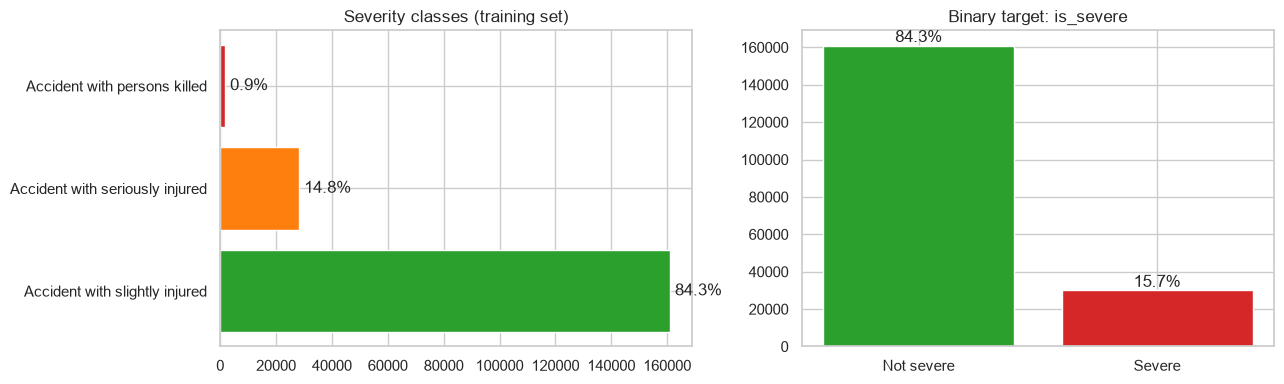

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
severity_counts = train["severity"].value_counts()
axes[0].barh(severity_counts.index, severity_counts.values, color=["tab:green", "tab:orange", "tab:red"])
axes[0].set_title("Severity classes (training set)")
for i, value in enumerate(severity_counts.values):
    axes[0].text(value, i, f" {value / len(train):.1%}", va="center")

binary_counts = y_train.map({0: "Not severe", 1: "Severe"}).value_counts()
axes[1].bar(binary_counts.index, binary_counts.values, color=["tab:green", "tab:red"])
axes[1].set_title("Binary target: is_severe")
for i, value in enumerate(binary_counts.values):
    axes[1].text(i, value, f"{value / len(train):.1%}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

84.3% of the training accidents are slight, 14.8% serious and only 0.9% fatal. Together, **15.7% are severe**, so the target is **imbalanced**: accuracy is misleading, and we use F1, recall and precision for the severe class.

### Time: Hour, Weekday and Month

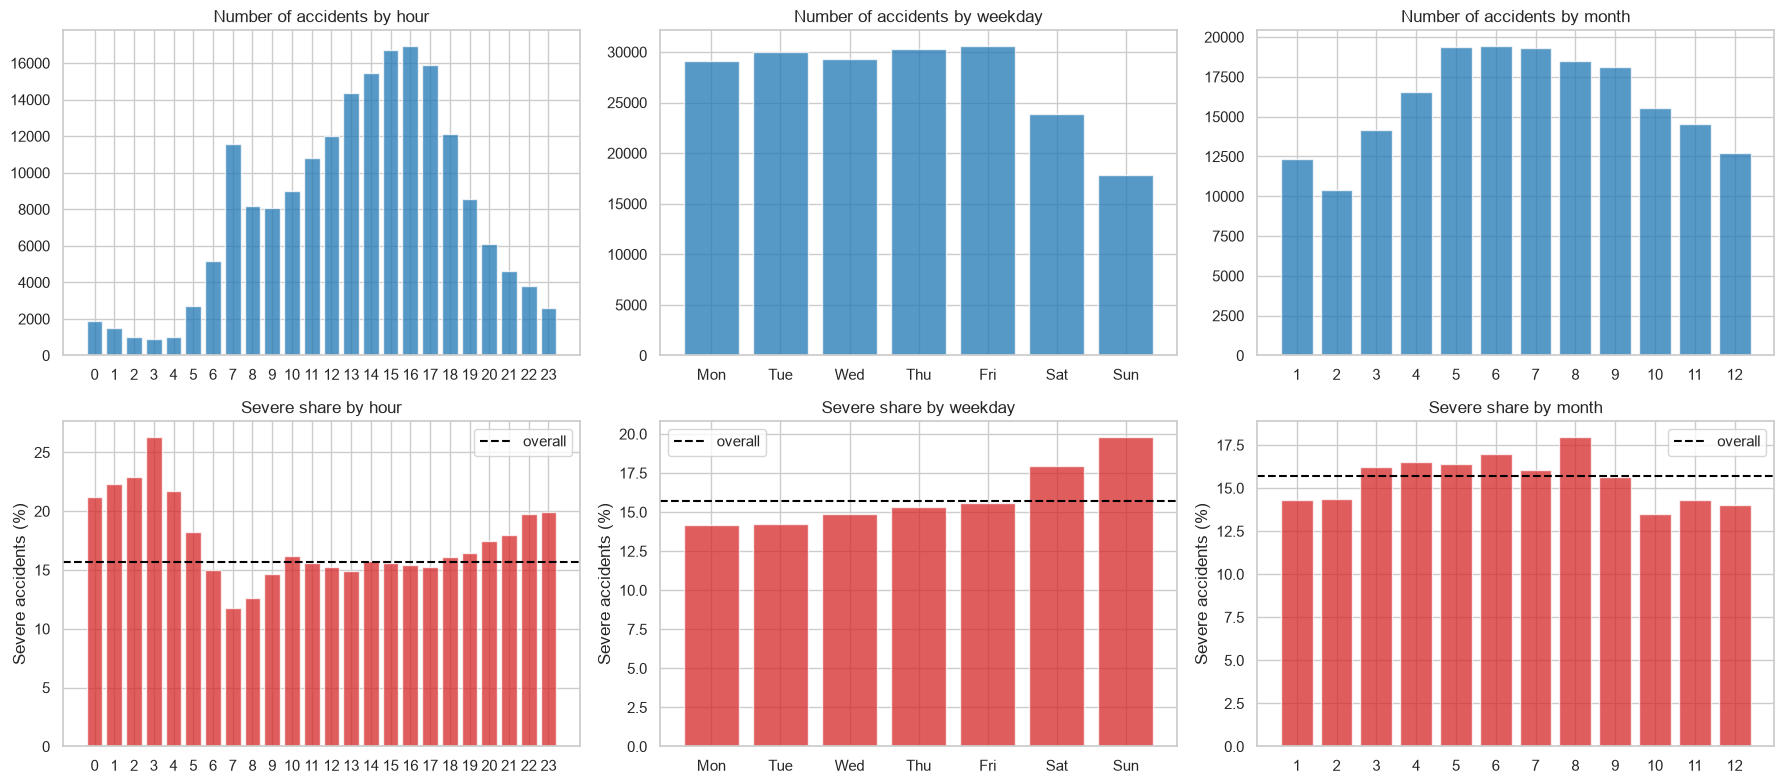

Severe share by hour (%): {0: 21.2, 1: 22.3, 2: 22.9, 3: 26.3, 4: 21.8, 5: 18.2, 6: 15.0, 7: 11.7, 8: 12.6, 9: 14.6, 10: 16.2, 11: 15.6, 12: 15.3, 13: 14.9, 14: 15.8, 15: 15.6, 16: 15.4, 17: 15.2, 18: 16.1, 19: 16.4, 20: 17.5, 21: 18.0, 22: 19.7, 23: 19.9}
Severe share by weekday (%): {'Monday': 14.2, 'Tuesday': 14.3, 'Wednesday': 14.9, 'Thursday': 15.3, 'Friday': 15.6, 'Saturday': 17.9, 'Sunday': 19.8}


In [12]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for col, (column, order) in enumerate([("hour", None), ("weekday", WEEKDAY_ORDER), ("month", None)]):
    stats = severe_share(train, column, order)
    labels = [s[:3] for s in stats.index.astype(str)] if column == "weekday" else stats.index.astype(str)
    axes[0, col].bar(labels, stats["size"], color="tab:blue", alpha=0.75)
    axes[0, col].set_title(f"Number of accidents by {column}")
    stats.index = labels
    plot_share(stats, axes[1, col], f"Severe share by {column}")
plt.tight_layout()
plt.show()

print("Severe share by hour (%):", severe_share(train, "hour")["mean"].round(1).to_dict())
print("Severe share by weekday (%):", severe_share(train, "weekday", WEEKDAY_ORDER)["mean"].round(1).to_dict())

- **Hour:** most accidents happen in the afternoon rush hour and at 07:00, but the **severe share is highest at night**: above average from about 18:00 to 05:00, peaking at **26.3% at 03:00**. The lowest share is at 07:00 (11.7%).
- **Weekday:** Monday to Friday have the most accidents, but **Saturday (17.9%) and Sunday (19.8%)** have the highest severe share.
- **Month:** summer has more accidents and a slightly higher severe share than winter.

Remember: these are **shares**, not counts. 07:00 still has many more severe accidents than 03:00, because so many more accidents happen then.

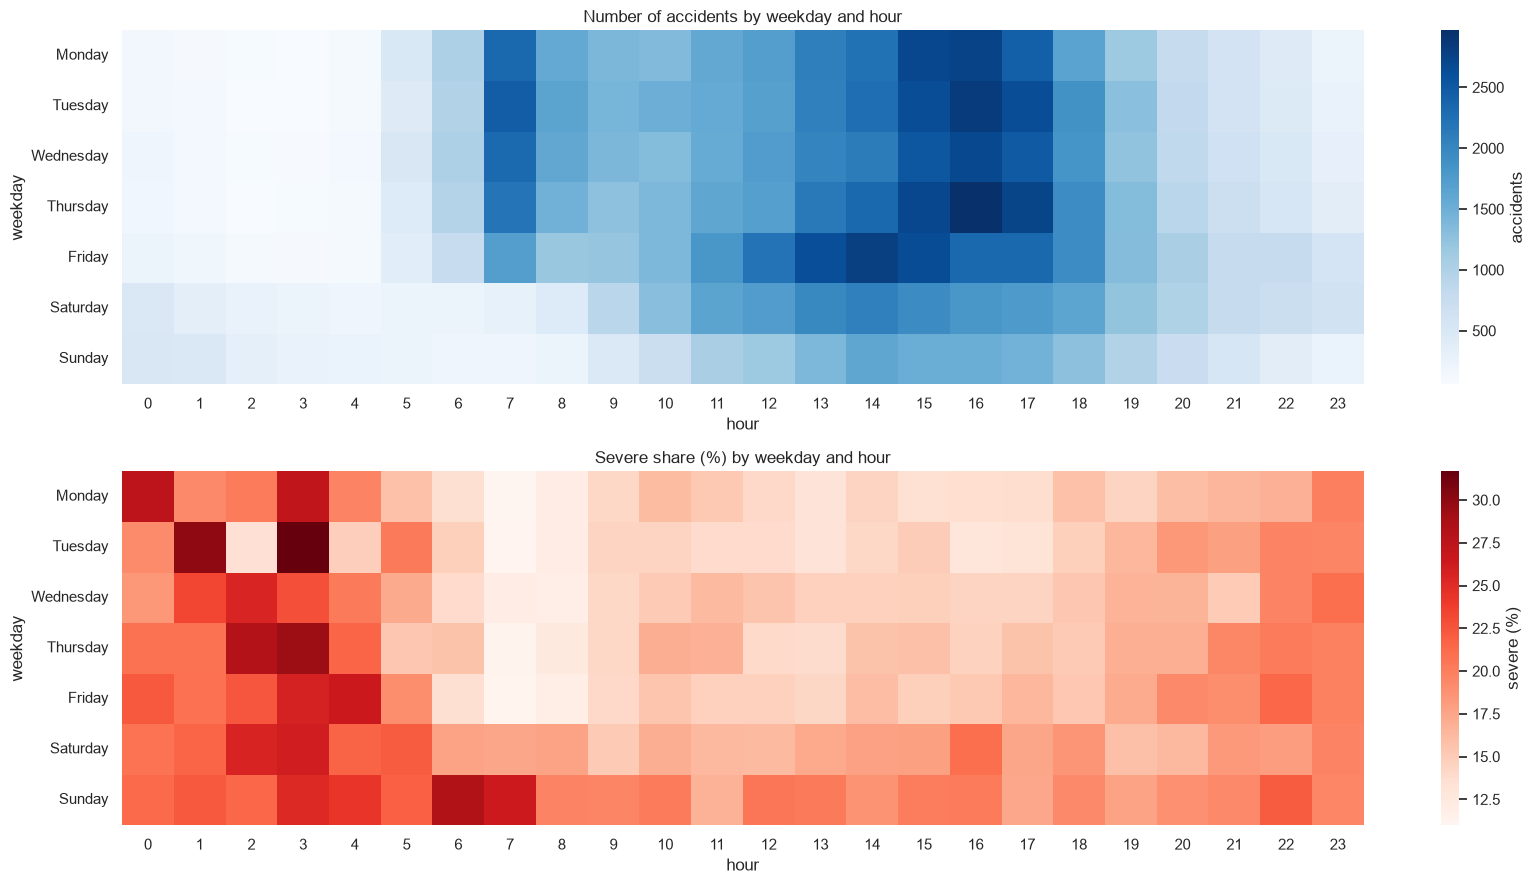

Busiest slots: {('Thursday', 16): 2967, ('Tuesday', 16): 2840, ('Friday', 14): 2786}
Quietest slots: {('Tuesday', 3): 60, ('Monday', 3): 66, ('Tuesday', 2): 67}
Highest severe share: {('Tuesday', 3): 31.7, ('Tuesday', 1): 30.0, ('Thursday', 3): 29.4, ('Sunday', 6): 28.3, ('Thursday', 2): 28.2}


In [13]:
fig, axes = plt.subplots(2, 1, figsize=(17, 9))

counts = train.pivot_table(index="weekday", columns="hour", values="is_severe", aggfunc="size")
counts = counts.reindex(WEEKDAY_ORDER)
sns.heatmap(counts, cmap="Blues", ax=axes[0], cbar_kws={"label": "accidents"})
axes[0].set_title("Number of accidents by weekday and hour")

rates = train.pivot_table(index="weekday", columns="hour", values="is_severe", aggfunc="mean") * 100
rates = rates.reindex(WEEKDAY_ORDER)
sns.heatmap(rates, cmap="Reds", ax=axes[1], cbar_kws={"label": "severe (%)"})
axes[1].set_title("Severe share (%) by weekday and hour")

plt.tight_layout()
plt.show()

print("Busiest slots:", counts.stack().sort_values(ascending=False).head(3).to_dict())
print("Quietest slots:", counts.stack().sort_values().head(3).to_dict())
print("Highest severe share:", rates.stack().sort_values(ascending=False).head(5).round(1).to_dict())

**Number of accidents (top):**

- On **weekdays**, accidents follow the commute: a morning peak at **07:00** and the busiest time in the **afternoon between 14:00 and 17:00**. The busiest slot is **Thursday 16:00** (2,967 training accidents).
- On **weekends** the pattern shifts: Saturday has most accidents from late morning to afternoon, Sunday is the quietest day, and there is no morning peak.
- Nights (00:00 to 05:00) are the quietest slots, with only about 60 accidents in some cells. Weekend nights have more accidents than weekday nights.

**Severe share (bottom):**

- The **night hours (00:00 to 05:00) are dark red on every day**, not only at the weekend. The highest values (for example Tuesday 03:00 with 31.7%) come from cells with only about 60 accidents, so single cells are noisy: read the overall band, not one cell.
- **Sunday morning (06:00 to 07:00)** is also very severe (about 28%): little traffic, probably higher speeds and people returning from Saturday night.
- **Weekend daytime** is generally more severe than weekday daytime.
- The **weekday morning rush (07:00 to 08:00)** is the palest area: many accidents, but mostly minor ones in slow, dense traffic.

**Together:** the two heatmaps are almost opposite. The busiest times have the lowest severe share, and the quietest times (nights, early Sunday morning) have the highest one.

### Light and Road Conditions

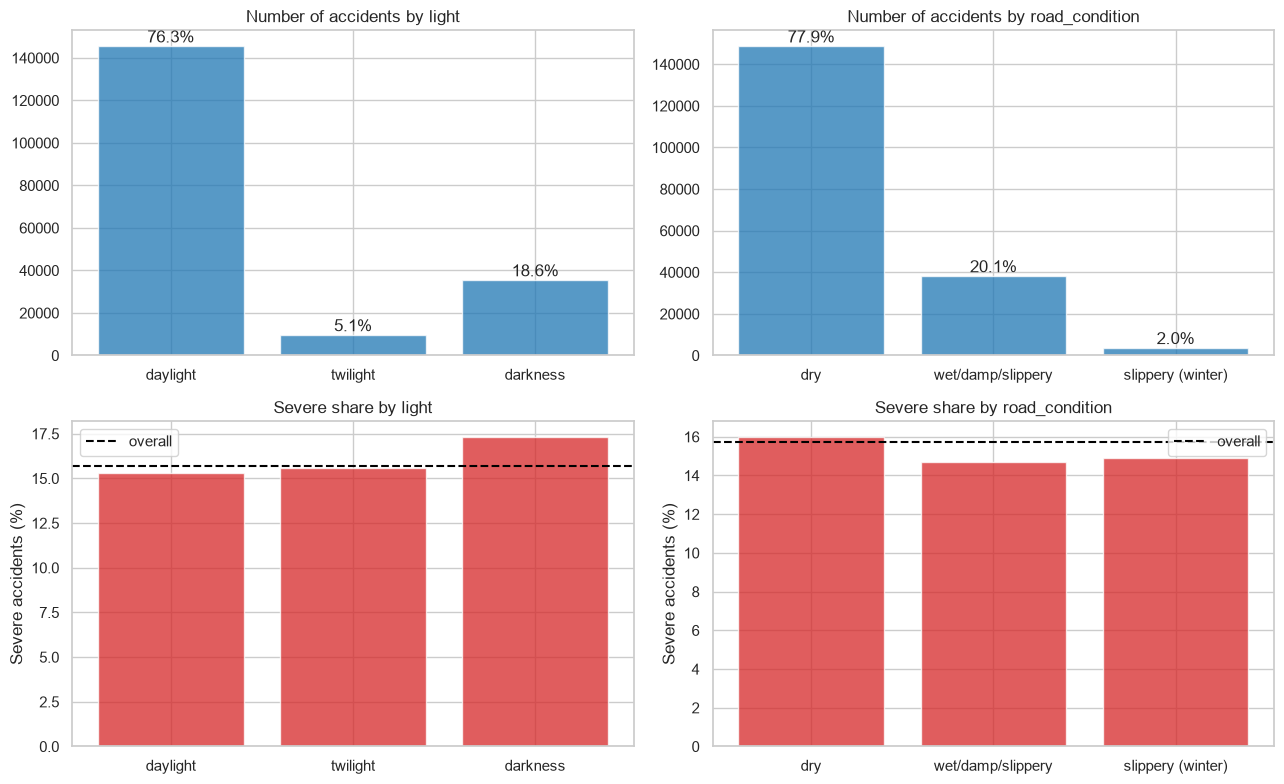

light {'darkness': 17.3, 'daylight': 15.3, 'twilight': 15.6}
road_condition {'dry': 16.0, 'slippery (winter)': 14.9, 'wet/damp/slippery': 14.7}


In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for col, (column, order) in enumerate([
    ("light", list(LIGHT_CODES)), ("road_condition", list(ROAD_CODES)),
]):
    stats = severe_share(train, column, order)
    axes[0, col].bar(stats.index, stats["size"], color="tab:blue", alpha=0.75)
    axes[0, col].set_title(f"Number of accidents by {column}")
    for i, value in enumerate(stats["size"]):
        axes[0, col].text(i, value, f"{value / len(train):.1%}", ha="center", va="bottom")
    plot_share(stats, axes[1, col], f"Severe share by {column}")
plt.tight_layout()
plt.show()

for column in ["light", "road_condition"]:
    print(column, severe_share(train, column)["mean"].round(1).to_dict())

- **Light:** 76% of accidents happen in daylight. Accidents in **darkness** are a bit more often severe (17.3% versus 15.3%).
- **Road:** 78% happen on dry roads. Wet and winter-slippery roads have a slightly **lower** severe share (about 14.8%) than dry roads (16.0%), probably because people drive more slowly in bad conditions.

Both effects are small.

### Participants

For each type of road user we compare the severe share when it is involved (red) and when it is not (grey).

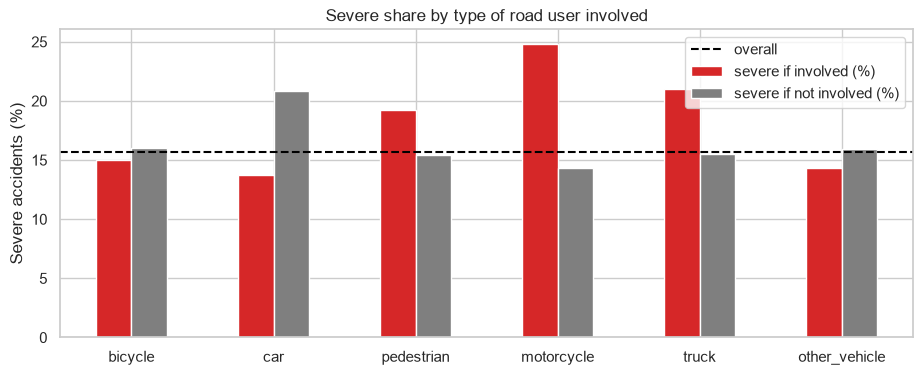

,involved (%),severe if involved (%),severe if not involved (%)
bicycle,32.8,15.0,16.0
car,72.3,13.7,20.8
pedestrian,8.9,19.2,15.4
motorcycle,13.5,24.8,14.3
truck,4.0,21.0,15.5
other_vehicle,14.5,14.3,15.9


In [15]:
participant_stats = pd.DataFrame({
    "involved (%)": [100 * train[c].mean() for c in PARTICIPANTS],
    "severe if involved (%)": [100 * train.loc[train[c] == 1, "is_severe"].mean() for c in PARTICIPANTS],
    "severe if not involved (%)": [100 * train.loc[train[c] == 0, "is_severe"].mean() for c in PARTICIPANTS],
}, index=PARTICIPANTS).round(1)

participant_stats[["severe if involved (%)", "severe if not involved (%)"]].plot.bar(
    figsize=(11, 4), color=["tab:red", "tab:gray"], rot=0)
plt.axhline(overall_rate, color="black", linestyle="--", label="overall")
plt.ylabel("Severe accidents (%)")
plt.title("Severe share by type of road user involved")
plt.legend()
plt.show()
participant_stats

- **Motorcycles** are the strongest signal: **24.8%** severe when involved, 14.3% when not.
- **Trucks** (21.0%) and **pedestrians** (19.2%) also raise the severe share.
- **Cars lower it:** 13.7% with a car versus 20.8% without, because car occupants are well protected.
- **Bicycles** are involved in a third of all accidents, with an average severe share (15.0%).

### Zina's Participant Features

- `n_participant_types`: how many of the six road-user groups are involved
- `vulnerable`: a pedestrian, bicycle or motorcycle is involved
- `single_type`: only one group of road users is involved (for example a car alone, or two cars)
- `vulnerable_vs_vehicle`: a vulnerable road user meets a car, truck or other vehicle

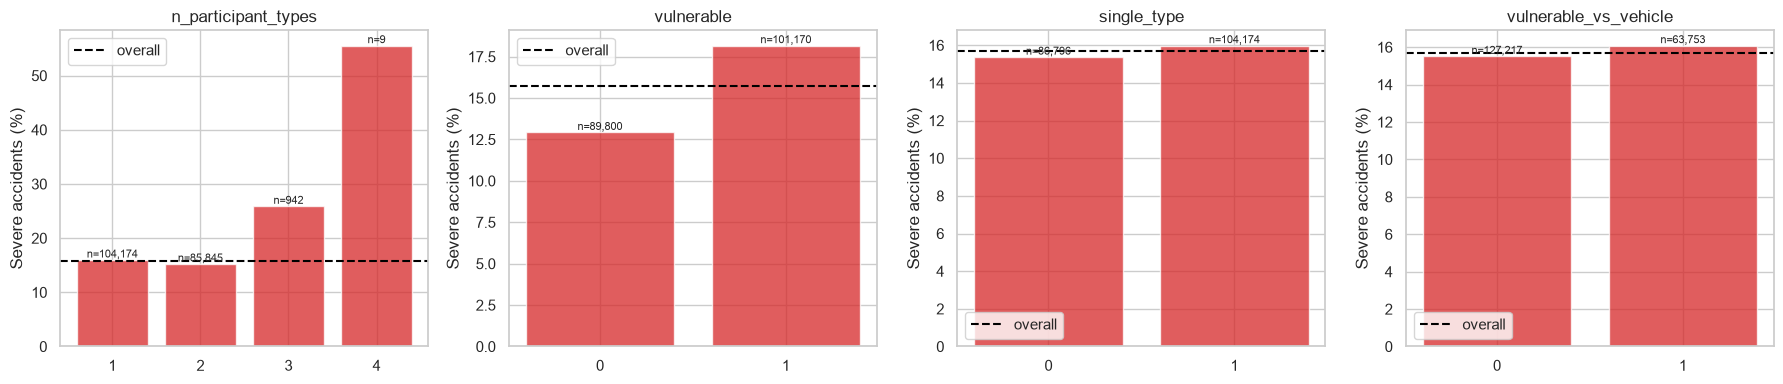

n_participant_types {1: {'mean': 16.0, 'size': 104174}, 2: {'mean': 15.3, 'size': 85845}, 3: {'mean': 25.9, 'size': 942}, 4: {'mean': 55.6, 'size': 9}}
vulnerable {0: {'mean': 12.9, 'size': 89800}, 1: {'mean': 18.2, 'size': 101170}}
single_type {0: {'mean': 15.4, 'size': 86796}, 1: {'mean': 16.0, 'size': 104174}}
vulnerable_vs_vehicle {0: {'mean': 15.5, 'size': 127217}, 1: {'mean': 16.1, 'size': 63753}}


In [16]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, column in zip(axes, ["n_participant_types", "vulnerable", "single_type", "vulnerable_vs_vehicle"]):
    stats = severe_share(train, column)
    plot_share(stats, ax, column)
    for i, (rate, size) in enumerate(zip(stats["mean"], stats["size"])):
        ax.text(i, rate, f"n={size:,}", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()

for column in ["n_participant_types", "vulnerable", "single_type", "vulnerable_vs_vehicle"]:
    print(column, severe_share(train, column).round(1).to_dict("index"))

- **`vulnerable`** is the most useful of Zina's flags: 18.2% severe when a pedestrian, bicycle or motorcycle is involved, versus 12.9% when not.
- **`n_participant_types`:** one or two groups behave alike (16.0% and 15.3%), but the rare accidents with **three groups** are much more often severe (25.9%; the 9 accidents with four groups are too few to judge).
- **`single_type`** and **`vulnerable_vs_vehicle`** barely change the severe share (about 15.5% to 16.1%). On their own they carry little signal.

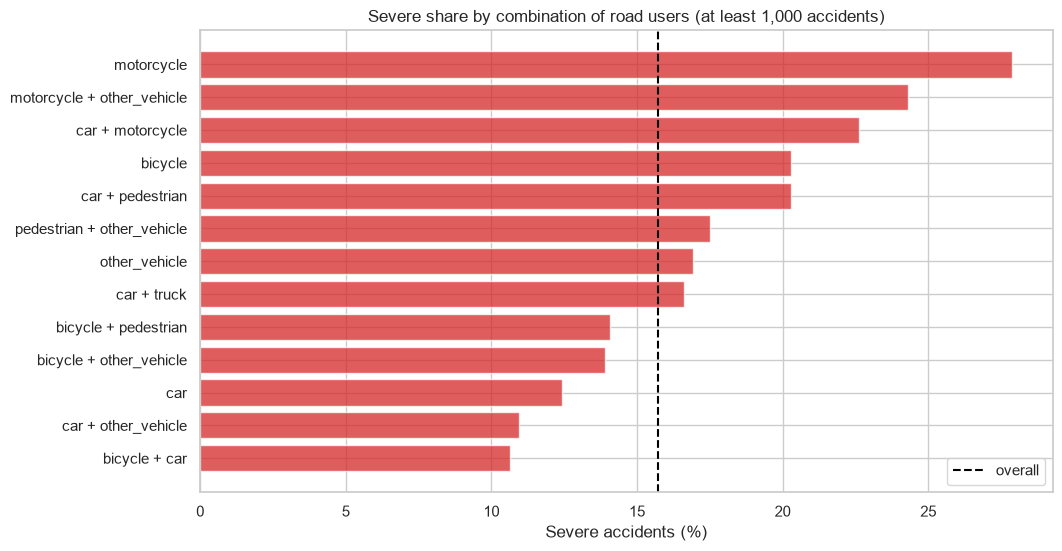

,mean,size
participants,,
motorcycle,27.9,9369
motorcycle + other_vehicle,24.3,1279
car + motorcycle,22.6,13406
bicycle,20.3,24121
car + pedestrian,20.3,10916
pedestrian + other_vehicle,17.5,2297
other_vehicle,16.9,5650
car + truck,16.6,4985
bicycle + pedestrian,14.1,2832


In [17]:
# The most common combinations of road users (at least 1,000 training accidents)
combos = severe_share(train, "participants")
combos = combos[combos["size"] >= 1000].sort_values("mean")

fig, ax = plt.subplots(figsize=(11, 6))
plot_share(combos, ax, "Severe share by combination of road users (at least 1,000 accidents)", horizontal=True)
plt.show()
combos.sort_values("mean", ascending=False).round(1)

The combinations show more than the single flags:

- **A motorcycle alone** (for example a rider losing control) is the most severe combination: **27.9%**, followed by motorcycle with another vehicle (24.3%) and car with motorcycle (22.6%).
- **A bicycle alone** is surprisingly severe (**20.3%**, the same as car with pedestrian), while **bicycle with car** is one of the least severe combinations (10.6%).
- **Car only** (12.4%) and **car with another vehicle** (10.9%) are the least severe.

The `participants` column itself is not in our feature list, but the model can learn these combinations from the six binary flags (tree models do this naturally).

### Urban versus Rural: Urbanisation and Population Density (Zina)

In the earlier EDA, the **urban versus rural** pattern showed up only indirectly through the states. Zina's municipality data lets us measure it directly.

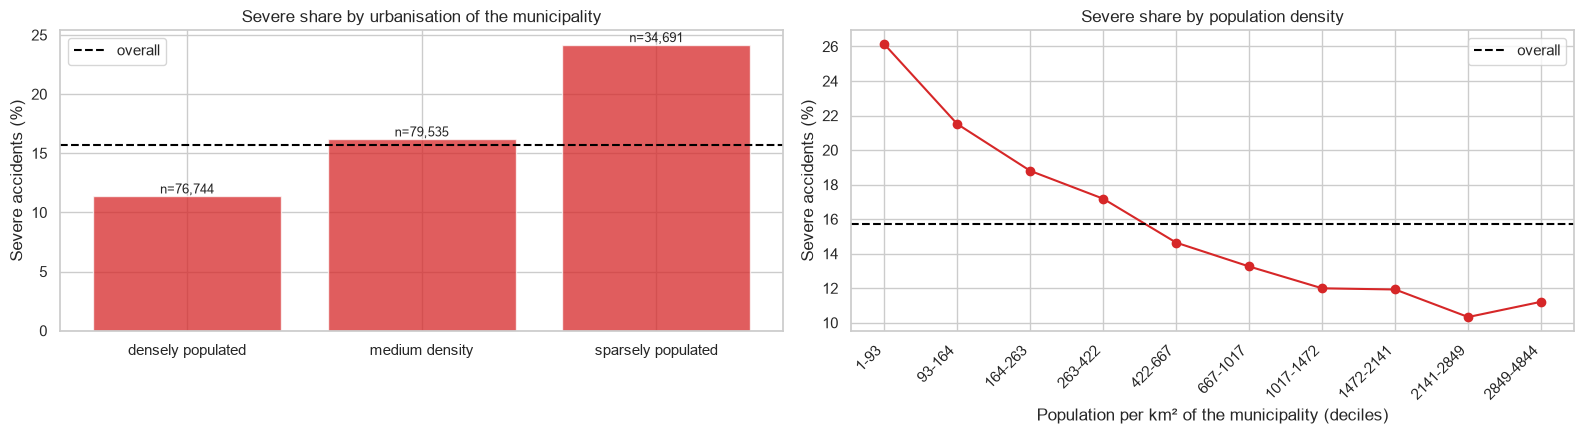

Urbanisation: {'densely populated': 11.4, 'medium density': 16.2, 'sparsely populated': 24.2}
Density deciles: [26.1, 21.5, 18.8, 17.2, 14.6, 13.3, 12.0, 11.9, 10.3, 11.2]


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
stats = severe_share(train, "urbanisation", list(URBANISATION_CODES))
plot_share(stats, axes[0], "Severe share by urbanisation of the municipality")
for i, (rate, size) in enumerate(zip(stats["mean"], stats["size"])):
    axes[0].text(i, rate, f"n={size:,}", ha="center", va="bottom", fontsize=9)

train["density_decile"] = pd.qcut(train["population_per_km2"], 10, duplicates="drop")
decile_stats = severe_share(train, "density_decile")
axes[1].plot(range(len(decile_stats)), decile_stats["mean"], marker="o", color="tab:red")
axes[1].axhline(overall_rate, color="black", linestyle="--", label="overall")
axes[1].set_xticks(range(len(decile_stats)))
axes[1].set_xticklabels([f"{int(i.left)}-{int(i.right)}" for i in decile_stats.index],
                        rotation=45, ha="right")
axes[1].set_xlabel("Population per km² of the municipality (deciles)")
axes[1].set_ylabel("Severe accidents (%)")
axes[1].set_title("Severe share by population density")
axes[1].legend()
plt.tight_layout()
plt.show()
train = train.drop(columns="density_decile")

print("Urbanisation:", stats["mean"].round(1).to_dict())
print("Density deciles:", decile_stats["mean"].round(1).tolist())

This is the **clearest pattern in the data**:

- Accidents in **sparsely populated** municipalities are severe in **24.2%** of cases, more than twice as often as in **densely populated** ones (**11.4%**).
- The severe share falls steadily with population density: from **26.1%** in the least dense tenth of accidents to about **10% to 11%** in the densest.

Rural roads mean higher speeds and longer rescue times; cities mean dense, slow traffic with many minor collisions. This explains the state pattern from the earlier EDA much more directly.

### Where Do Accidents Happen? States and Maps

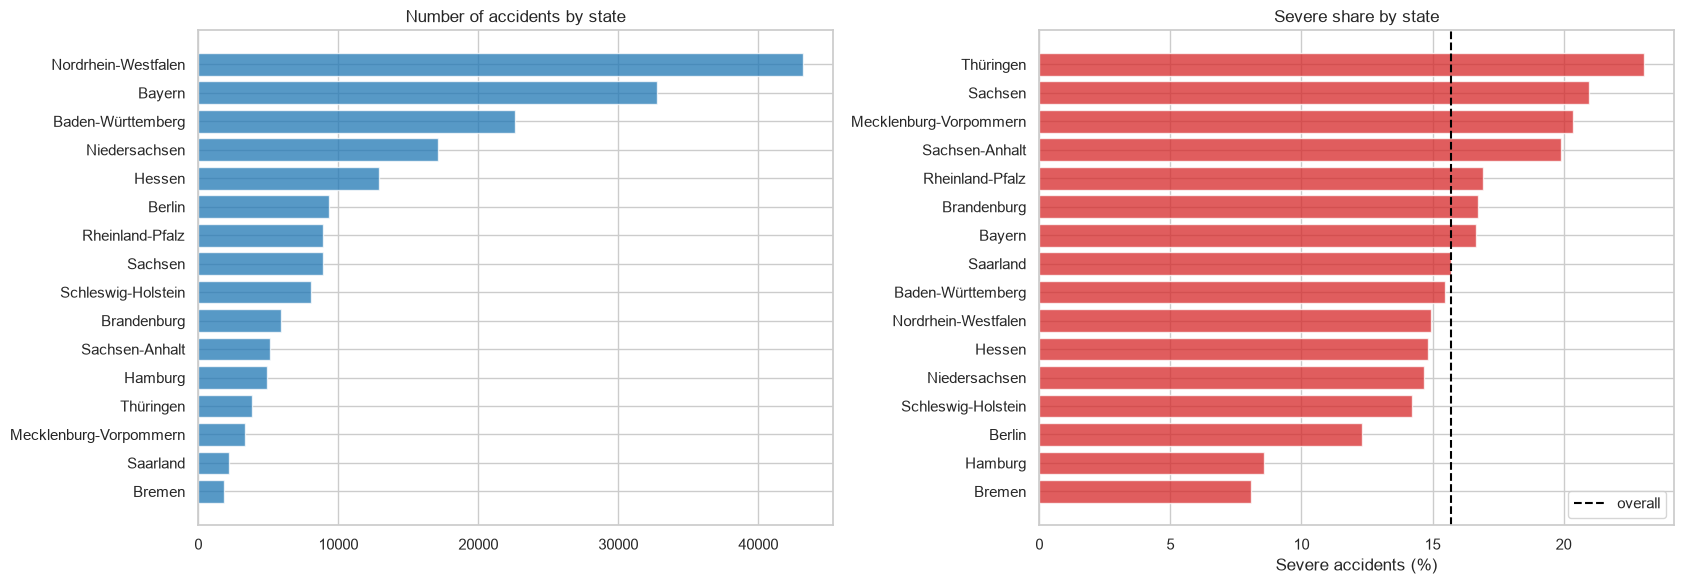

{'Bremen': 8.1, 'Hamburg': 8.6, 'Berlin': 12.3, 'Schleswig-Holstein': 14.2, 'Niedersachsen': 14.7, 'Hessen': 14.8, 'Nordrhein-Westfalen': 15.0, 'Baden-Württemberg': 15.5, 'Saarland': 15.7, 'Bayern': 16.7, 'Brandenburg': 16.7, 'Rheinland-Pfalz': 16.9, 'Sachsen-Anhalt': 19.9, 'Mecklenburg-Vorpommern': 20.3, 'Sachsen': 21.0, 'Thüringen': 23.1}


In [19]:
STATE_NAMES = train.groupby("state")["state_name"].first()
state_stats = severe_share(train, "state")
state_stats.index = state_stats.index.map(STATE_NAMES)
state_stats = state_stats.sort_values("mean")

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
axes[0].barh(state_stats.sort_values("size").index, state_stats.sort_values("size")["size"],
             color="tab:blue", alpha=0.75)
axes[0].set_title("Number of accidents by state")
plot_share(state_stats, axes[1], "Severe share by state", horizontal=True)
plt.tight_layout()
plt.show()
print(state_stats["mean"].round(1).to_dict())

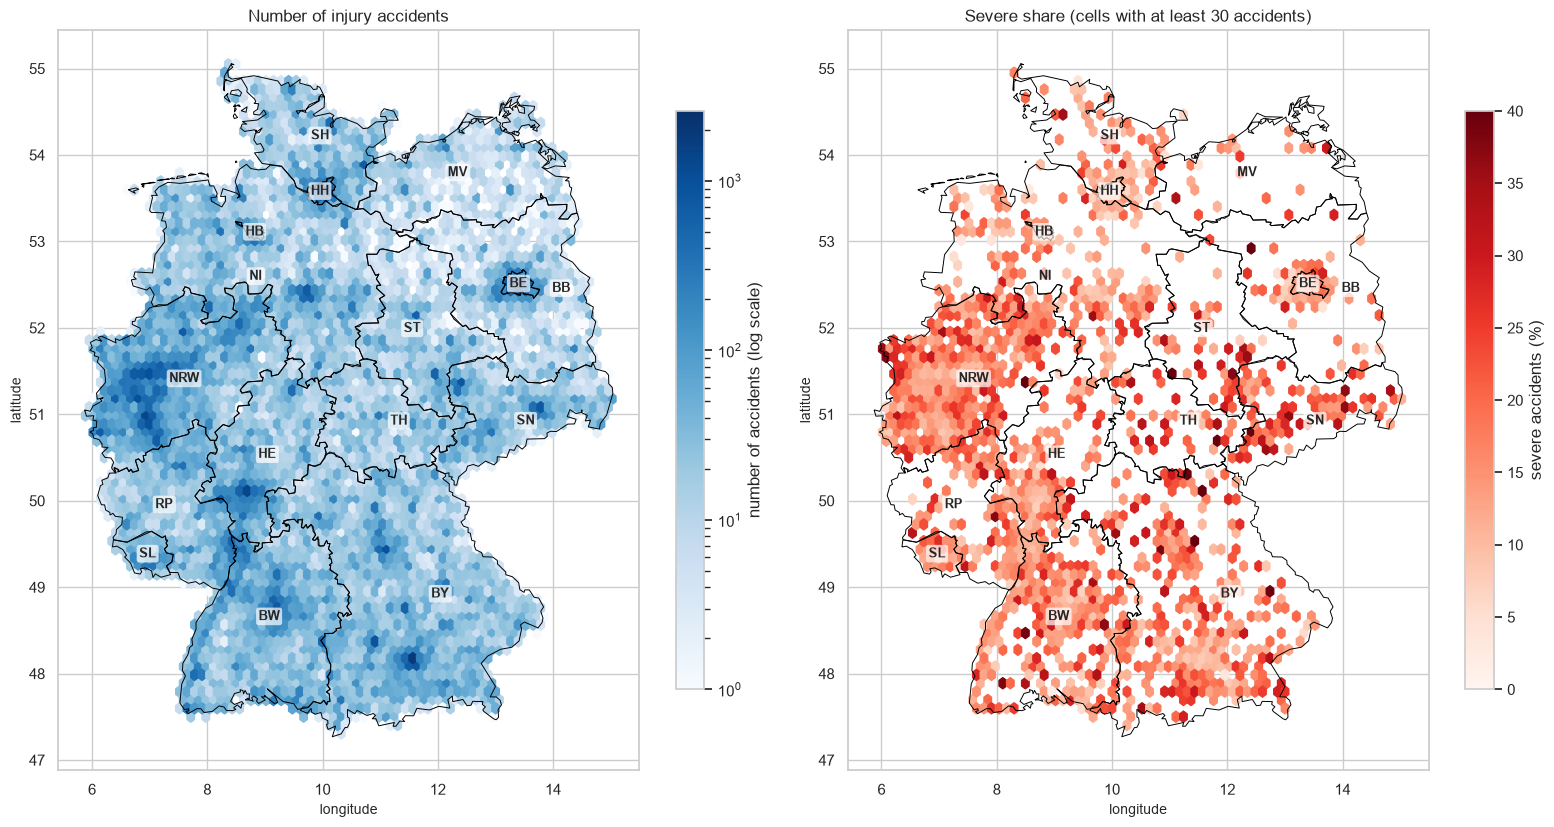

In [20]:
STATE_BORDERS_URL = (
    "https://raw.githubusercontent.com/isellsoap/deutschlandGeoJSON/"
    "main/2_bundeslaender/4_niedrig.geo.json"
)
# Download first: reading the URL directly with geopandas can hang on some networks
with urllib.request.urlopen(STATE_BORDERS_URL, timeout=30) as response:
    state_borders = gpd.read_file(io.BytesIO(response.read()))
state_borders["label"] = state_borders["id"].str.replace("DE-", "").replace({"NW": "NRW"})

fig, axes = plt.subplots(1, 2, figsize=(16, 10))
hb = axes[0].hexbin(train["longitude"], train["latitude"], gridsize=70, bins="log", cmap="Blues", mincnt=1)
fig.colorbar(hb, ax=axes[0], label="number of accidents (log scale)", shrink=0.6)
axes[0].set_title("Number of injury accidents")
hb = axes[1].hexbin(train["longitude"], train["latitude"], C=train["is_severe"] * 100,
                    reduce_C_function=np.mean, gridsize=70, cmap="Reds", mincnt=30, vmin=0, vmax=40)
fig.colorbar(hb, ax=axes[1], label="severe accidents (%)", shrink=0.6)
axes[1].set_title("Severe share (cells with at least 30 accidents)")
for ax in axes:
    state_borders.boundary.plot(ax=ax, color="black", linewidth=0.7)
    for _, state in state_borders.iterrows():
        point = state.geometry.representative_point()
        ax.annotate(state["label"], (point.x, point.y), ha="center", va="center", fontsize=9,
                    fontweight="bold", bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.7))
    ax.set_xlabel("longitude")
    ax.set_ylabel("latitude")
    ax.set_aspect(1.5)
plt.tight_layout()
plt.show()

- The **city states Bremen (8.1%), Hamburg (8.6%) and Berlin (12.3%)** have the lowest severe share; the eastern states **Thuringia (23.1%), Saxony (21.0%), Mecklenburg-Vorpommern (20.3%) and Saxony-Anhalt (19.9%)** the highest.
- On the maps, the accidents cluster in the big cities (Ruhr area, Berlin, Hamburg, Munich, Frankfurt, Stuttgart), where the severe share is low. Rural areas between the cities are darker red.
- White areas on the right map are cells with fewer than 30 accidents, not areas without severe accidents.

### Age Structure per State (Zina)

The age features have only 16 different values (one per state), so we compare them with the severe share per state.

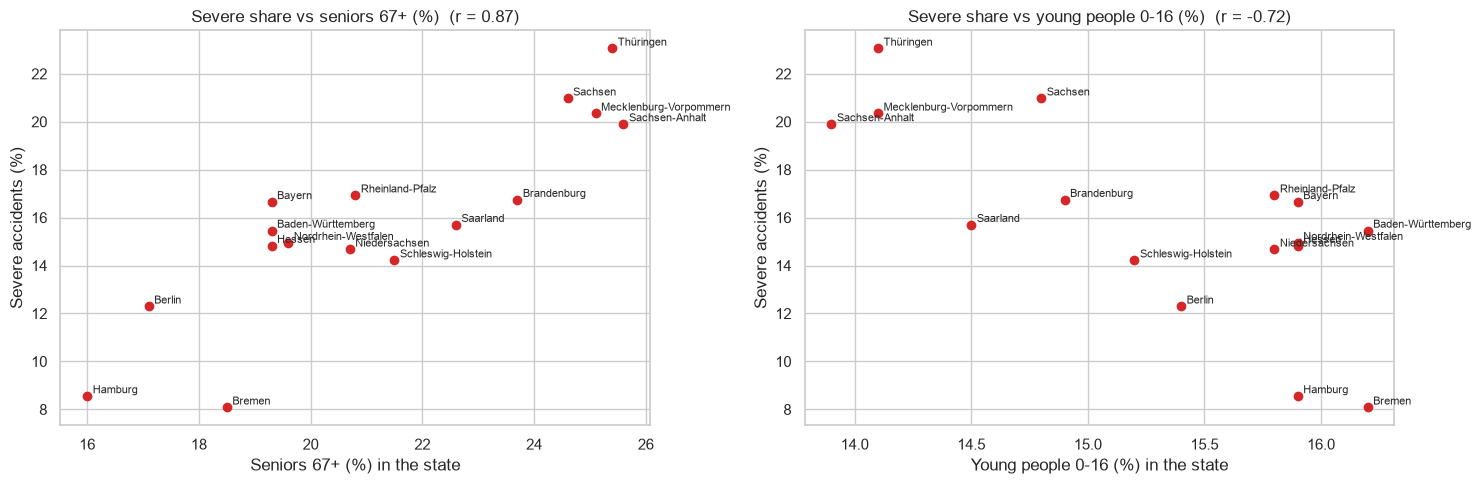

In [21]:
state_view = train.groupby("state").agg(
    severe_pct=("is_severe", lambda s: 100 * s.mean()),
    senior_pct=("state_senior_67_plus_pct", "first"),
    young_pct=("state_young_0_16_pct", "first"),
    name=("state_name", "first"),
)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, column, label in [(axes[0], "senior_pct", "Seniors 67+ (%)"), (axes[1], "young_pct", "Young people 0-16 (%)")]:
    ax.scatter(state_view[column], state_view["severe_pct"], color="tab:red")
    for _, row in state_view.iterrows():
        ax.annotate(row["name"], (row[column], row["severe_pct"]), fontsize=8, xytext=(4, 2),
                    textcoords="offset points")
    r = state_view[[column, "severe_pct"]].corr().iloc[0, 1]
    ax.set_xlabel(f"{label} in the state")
    ax.set_ylabel("Severe accidents (%)")
    ax.set_title(f"Severe share vs {label.lower()}  (r = {r:.2f})")
plt.tight_layout()
plt.show()

At state level, the share of **seniors (67+)** goes together with a higher severe share (**r = 0.87**), and the share of **young people (0 to 16)** with a lower one (**r = -0.72**).

⚠️ These correlations are based on only **16 points**, and age is mixed up with **urban versus rural**: the eastern states are both older and more rural. An older population does not necessarily cause more severe accidents. With the much more detailed urbanisation and density features, the models will show whether the age features add anything.

### Districts and Municipalities

Districts: 512 | Municipalities: 8965
Districts with at least 100 accidents: 413
Severe share: min 3.8%, median 16.8%, max 35.5%
Validation accidents in municipalities not seen in training: 310


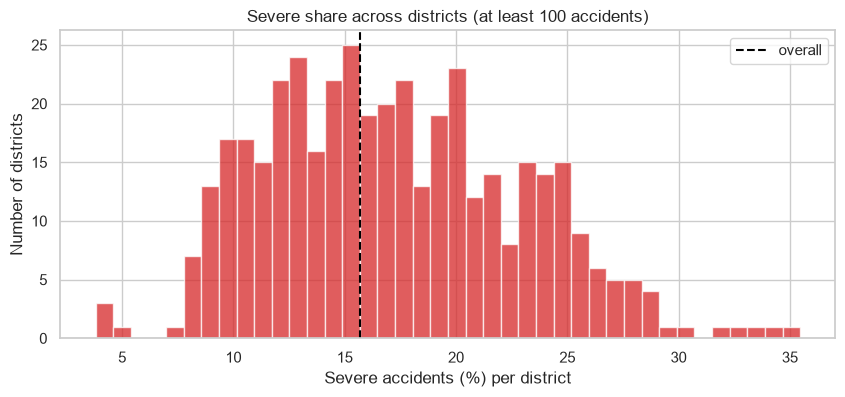

In [22]:
print("Districts:", train["district"].nunique(), "| Municipalities:", train["municipality"].nunique())
district_stats = severe_share(train, "district")
large = district_stats[district_stats["size"] >= 100]
print("Districts with at least 100 accidents:", len(large))
print("Severe share: min %.1f%%, median %.1f%%, max %.1f%%" % (
    large["mean"].min(), large["mean"].median(), large["mean"].max()))
unseen = ~val["municipality"].isin(set(train["municipality"]))
print("Validation accidents in municipalities not seen in training:", int(unseen.sum()))

plt.figure(figsize=(10, 4))
plt.hist(large["mean"], bins=40, color="tab:red", alpha=0.75)
plt.axvline(overall_rate, color="black", linestyle="--", label="overall")
plt.xlabel("Severe accidents (%) per district")
plt.ylabel("Number of districts")
plt.title("Severe share across districts (at least 100 accidents)")
plt.legend()
plt.show()

The training set covers **512 districts** and **8,965 municipalities**. Among the 413 districts with at least 100 accidents, the severe share ranges from **3.8% to 35.5%** (median 16.8%), a much wider spread than between states. So the district carries detailed location information, which we use through target encoding.

310 validation accidents happen in municipalities that never appear in the training set. The target encoder gives them the overall mean, so this does not break anything.

### Which Features Are Related to Each Other?

1. **Pearson correlation** for the binary, ordinal and numeric features and the target.
2. **Cramér's V** for the categorical features (0 = no association, 1 = perfect association), which does not depend on the order of the codes.

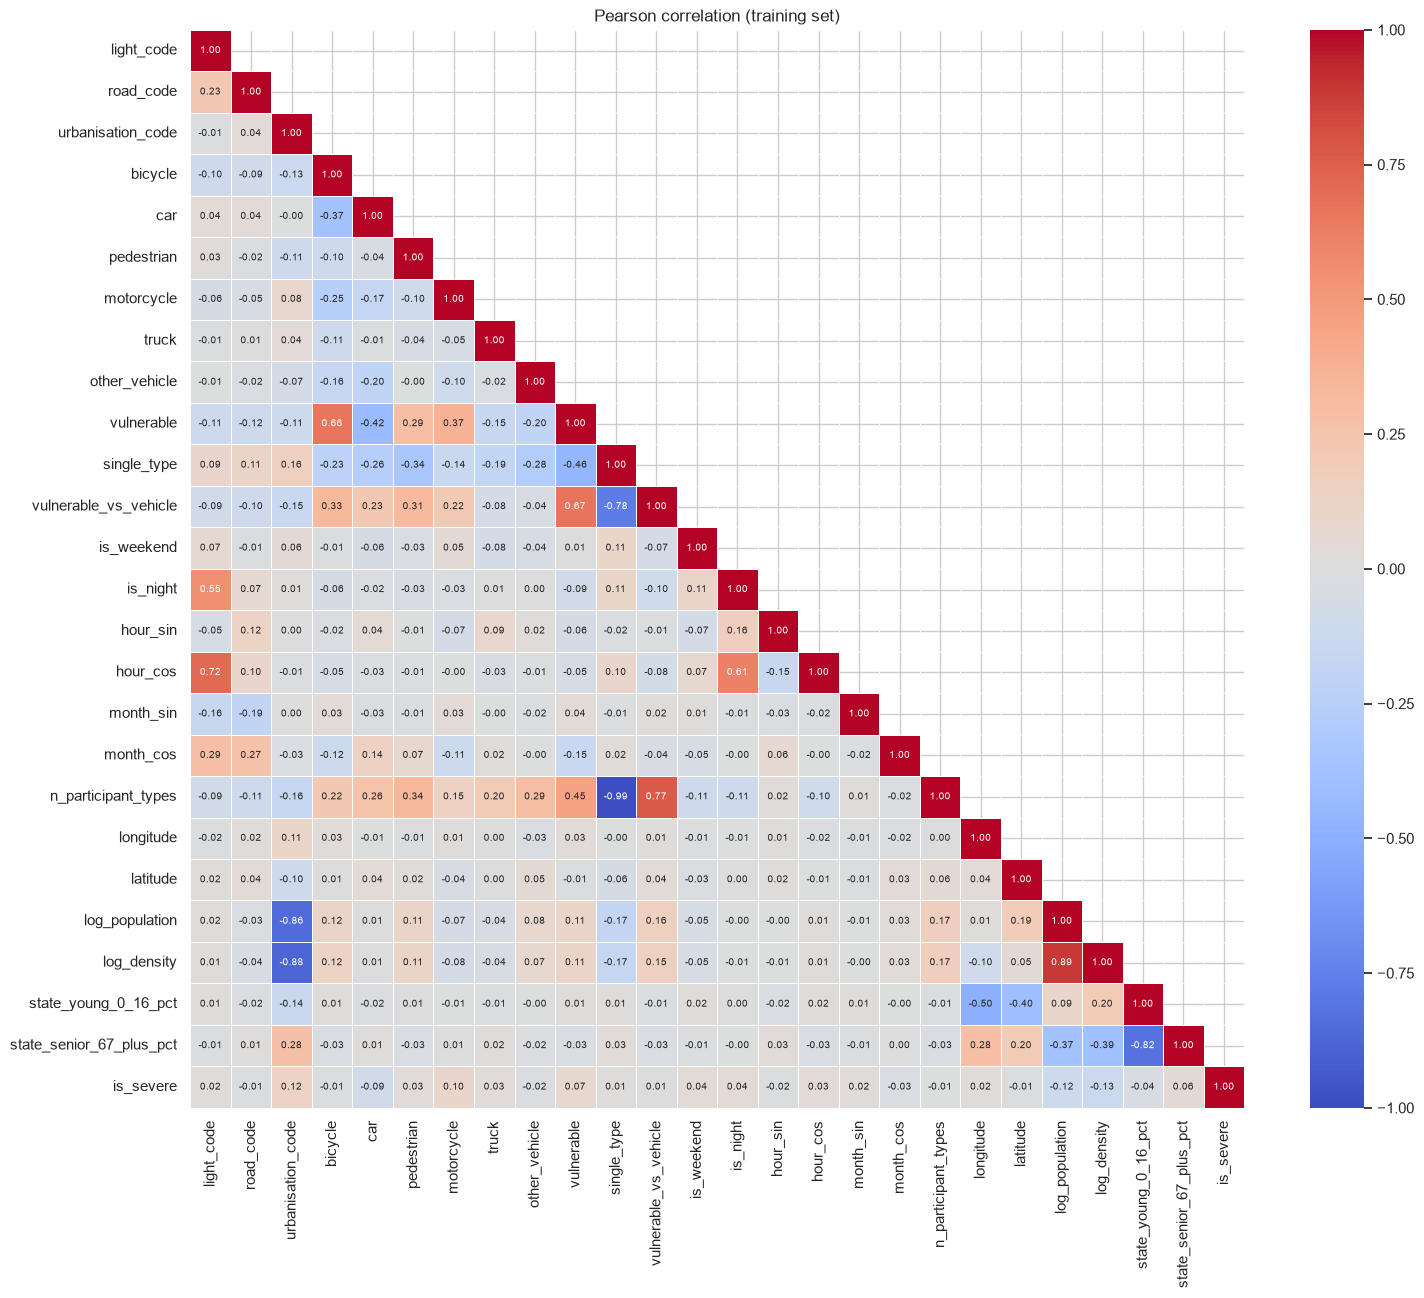

Strongest pairs:
single_type            n_participant_types        -0.99
log_population         log_density                 0.89
urbanisation_code      log_density                -0.88
                       log_population             -0.86
state_young_0_16_pct   state_senior_67_plus_pct   -0.82
single_type            vulnerable_vs_vehicle      -0.78
vulnerable_vs_vehicle  n_participant_types         0.77
light_code             hour_cos                    0.72
vulnerable             vulnerable_vs_vehicle       0.67
bicycle                vulnerable                  0.66
dtype: float64

Correlation with is_severe:
log_density                -0.132
log_population             -0.116
car                        -0.087
state_young_0_16_pct       -0.041
month_cos                  -0.026
other_vehicle              -0.016
hour_sin                   -0.015
latitude                   -0.014
road_code                  -0.014
bicycle                    -0.013
n_participant_types        -0.005
vulne

In [23]:
corr_columns = ORDINAL + BINARY + NUMERIC + ["is_severe"]
pearson = train[corr_columns].corr()

plt.figure(figsize=(17, 14))
mask = np.triu(np.ones_like(pearson, dtype=bool), k=1)
sns.heatmap(pearson, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=0.5, annot_kws={"size": 7})
plt.title("Pearson correlation (training set)")
plt.show()

features_only = pearson.drop(index="is_severe", columns="is_severe")
pairs = features_only.where(np.triu(np.ones(features_only.shape, dtype=bool), k=1)).stack()
print("Strongest pairs:")
print(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(10).round(2))
print("\nCorrelation with is_severe:")
print(pearson["is_severe"].drop("is_severe").sort_values().round(3))

**Redundant features** (very strong correlations):

- `single_type` and `n_participant_types` (**-0.99**): an accident with only one group of road users is exactly an accident with `n_participant_types` = 1. For linear models we should keep only one of them.
- `log_population`, `log_density` and `urbanisation_code` (**0.85 to 0.89** in absolute value): all three measure how urban the place is.
- The two state age shares (**-0.82**).
- `light_code` and `hour_cos` (0.72): night means darkness.

**Correlation with the target:** the strongest linear signals are now the **urban-rural features** (`log_density` -0.13, `urbanisation_code` +0.12, `log_population` -0.12), ahead of `motorcycle` (+0.10) and `car` (-0.09). All values are small, so the model has to combine many weak signals.

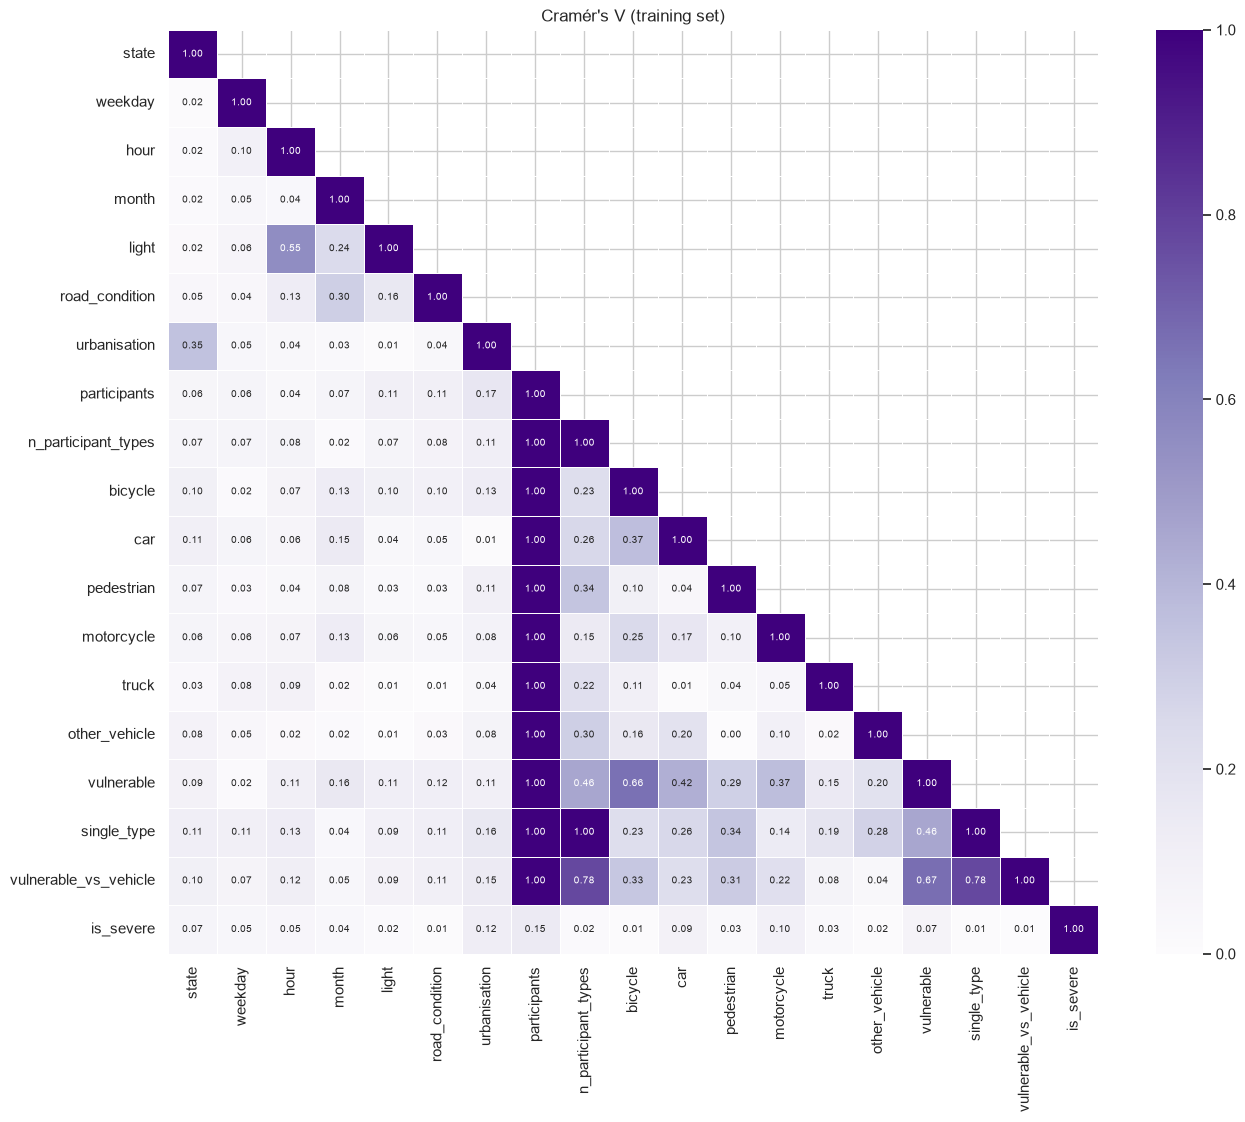

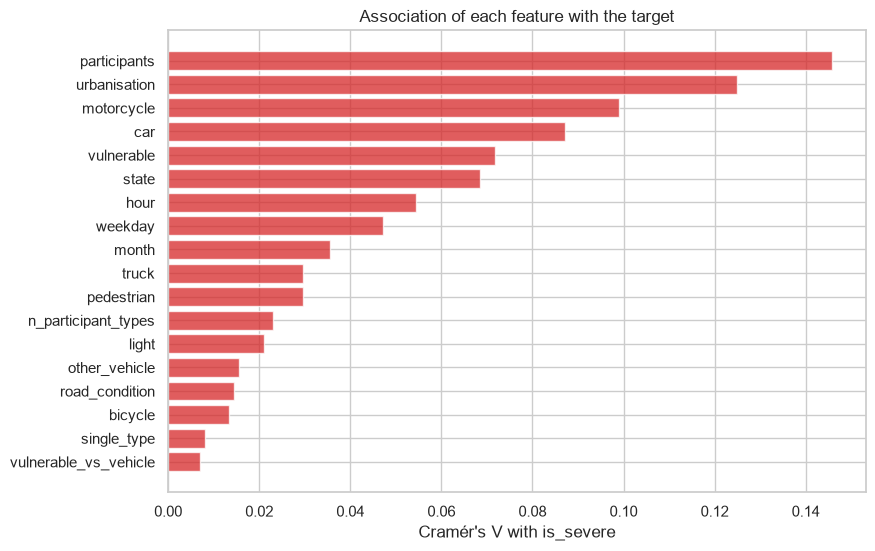

{'participants': 0.146, 'urbanisation': 0.125, 'motorcycle': 0.099, 'car': 0.087, 'vulnerable': 0.072, 'state': 0.068, 'hour': 0.054, 'weekday': 0.047, 'month': 0.036, 'truck': 0.03, 'pedestrian': 0.03, 'n_participant_types': 0.023, 'light': 0.021, 'other_vehicle': 0.016, 'road_condition': 0.014, 'bicycle': 0.013, 'single_type': 0.008, 'vulnerable_vs_vehicle': 0.007}


In [24]:
from scipy.stats import chi2_contingency


def cramers_v(x, y):
    """Bias-corrected Cramer's V between two categorical series."""
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    r, k = table.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r_corr, k_corr = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(k_corr - 1, r_corr - 1))


categorical = ["state", "weekday", "hour", "month", "light", "road_condition", "urbanisation",
               "participants", "n_participant_types"] + PARTICIPANTS + [
               "vulnerable", "single_type", "vulnerable_vs_vehicle", "is_severe"]
cramers = pd.DataFrame(index=categorical, columns=categorical, dtype=float)
for i, a in enumerate(categorical):
    for b in categorical[i:]:
        value = 1.0 if a == b else cramers_v(train[a], train[b])
        cramers.loc[a, b] = cramers.loc[b, a] = value

plt.figure(figsize=(15, 12))
mask = np.triu(np.ones_like(cramers, dtype=bool), k=1)
sns.heatmap(cramers, mask=mask, annot=True, fmt=".2f", cmap="Purples", vmin=0, vmax=1, linewidths=0.5,
            annot_kws={"size": 7})
plt.title("Cramér's V (training set)")
plt.show()

target_association = cramers["is_severe"].drop("is_severe").sort_values()
plt.figure(figsize=(9, 6))
plt.barh(target_association.index, target_association.values, color="tab:red", alpha=0.75)
plt.xlabel("Cramér's V with is_severe")
plt.title("Association of each feature with the target")
plt.show()
print(target_association.sort_values(ascending=False).round(3).to_dict())

The **combination of road users** (`participants`, 0.15) and **urbanisation** (0.13) have the strongest association with severity, followed by `motorcycle`, `car`, `vulnerable`, `state` and `hour`. Zina's new features add real signal: urbanisation is now the second strongest single feature.

### EDA Summary

- **Target:** 15.7% of injury accidents are severe, so the data is imbalanced.
- **Urban versus rural is the clearest pattern:** sparsely populated municipalities 24.2% severe, densely populated 11.4%. Zina's urbanisation and density features capture it directly.
- **Road users:** motorcycles (especially alone), trucks and pedestrians raise the risk; cars lower it. Zina's `vulnerable` flag summarises this well.
- **Time:** nights and weekends have the highest severe share.
- **Place:** city states are the least severe, eastern rural states the most severe; districts vary even more (3.8% to 35.5%).
- **Redundancy:** `single_type` and `n_participant_types`, and the three urban-rural features, are strongly correlated with each other.

## 9. Feature Engineering: Interaction Features

The EDA showed that some risks depend on **combinations**: a motorcycle is much more dangerous on a rural road than in a city (Jishnu's EDA: 34.6% versus 16.4% severe), and a motorcycle **alone** is the most severe participant combination (27.9%). Tree models can learn such combinations by themselves, but explicit flags can make it easier, and they help linear models a lot.

All new features are **0/1 flags computed row by row** from existing columns, so they learn nothing from the data and are leakage-free:

| Feature | Definition | Idea from the EDA |
|---|---|---|
| `motorcycle_rural` | motorcycle AND sparsely populated municipality | Motorcycles are most dangerous on rural roads |
| `vulnerable_rural` | pedestrian, bicycle or motorcycle AND sparsely populated | Unprotected road users plus high speeds |
| `motorcycle_alone` | motorcycle AND only one road-user group | Motorcycle alone: 27.9% severe |
| `bicycle_alone` | bicycle AND only one road-user group | Bicycle alone: 20.3% severe (versus 10.6% with a car) |
| `weekend_night` | weekend AND night (22:00 to 05:59) | Weekend nights are among the most severe hours |
| `pedestrian_dark` | pedestrian AND darkness | Pedestrians are hard to see in the dark |
| `motorcycle_weekend` | motorcycle AND weekend | Leisure rides at the weekend |

In [25]:
INTERACTIONS = ["motorcycle_rural", "vulnerable_rural", "motorcycle_alone", "bicycle_alone",
                "weekend_night", "pedestrian_dark", "motorcycle_weekend"]


def add_interactions(data):
    """Add the 0/1 interaction flags (row by row, no learning)."""
    rural = data["urbanisation_code"] == 2
    alone = data["n_participant_types"] == 1
    data["motorcycle_rural"] = ((data["motorcycle"] == 1) & rural).astype(int)
    data["vulnerable_rural"] = ((data["vulnerable"] == 1) & rural).astype(int)
    data["motorcycle_alone"] = ((data["motorcycle"] == 1) & alone).astype(int)
    data["bicycle_alone"] = ((data["bicycle"] == 1) & alone).astype(int)
    data["weekend_night"] = ((data["is_weekend"] == 1) & (data["is_night"] == 1)).astype(int)
    data["pedestrian_dark"] = ((data["pedestrian"] == 1) & (data["light_code"] == 2)).astype(int)
    data["motorcycle_weekend"] = ((data["motorcycle"] == 1) & (data["is_weekend"] == 1)).astype(int)
    return data


for data in (train, val, test):
    add_interactions(data)

# Quick look on the training set: how common is each flag, and how severe are those accidents?
pd.DataFrame({
    "share of accidents (%)": [100 * train[f].mean() for f in INTERACTIONS],
    "severe if flag = 1 (%)": [100 * train.loc[train[f] == 1, "is_severe"].mean() for f in INTERACTIONS],
    "severe if flag = 0 (%)": [100 * train.loc[train[f] == 0, "is_severe"].mean() for f in INTERACTIONS],
}, index=INTERACTIONS).round(1)

,share of accidents (%),severe if flag = 1 (%),severe if flag = 0 (%)
motorcycle_rural,3.5,35.1,15.0
vulnerable_rural,7.7,29.8,14.5
motorcycle_alone,4.9,27.9,15.1
bicycle_alone,12.6,20.3,15.0
weekend_night,3.1,21.5,15.5
pedestrian_dark,1.9,23.7,15.6
motorcycle_weekend,3.7,29.6,15.2


All seven flags mark **high-risk combinations** in the training data, as expected from the EDA:

- **`motorcycle_rural`** is the strongest: **35.1%** of these accidents are severe (versus 15.0% for all others), but it covers only 3.5% of accidents.
- `vulnerable_rural` (29.8%), `motorcycle_weekend` (29.6%) and `motorcycle_alone` (27.9%) are also far above the average.
- `weekend_night` (21.5%), `pedestrian_dark` (23.7%) and `bicycle_alone` (20.3%) are moderately above it.

Whether they **improve the model** is a different question: a tree model may already find these combinations by itself. The ablation study below tests this.

## 10. Preprocessing Pipeline

Everything that **learns** from the data is fitted on the **training set only**, then only applied (`transform`) to the validation and test sets.

| Group | Step | Why |
|---|---|---|
| `state` | One-hot encoding | The codes 1 to 16 have no order |
| `district`, `municipality` | Target encoding with internal cross fitting | 513 and 9,479 categories are too many for one-hot encoding |
| Numeric | Median imputation, then standard scaling | Our data has no missing values, but new data might; scaling helps linear models |
| Ordinal | Most-frequent imputation | A safety net in case new data has missing values |
| Binary | Passed through | Already 0 or 1 |

In the modelling phase, `make_preprocessor()` goes **inside** each model's `Pipeline`, so cross validation refits it in every fold.

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder


def make_preprocessor():
    """Build a fresh, unfitted preprocessing step for the Scenario C features."""
    return ColumnTransformer(
        [
            ("onehot", OneHotEncoder(handle_unknown="ignore"), NOMINAL),
            ("target_encoding", TargetEncoder(
                target_type="binary", cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
            ), HIGH_CARDINALITY),
            ("numeric", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUMERIC),
            ("ordinal", SimpleImputer(strategy="most_frequent"), ORDINAL),
            ("binary", "passthrough", BINARY),
        ],
        verbose_feature_names_out=False,
    )


preprocessor = make_preprocessor()
X_train_prepared = preprocessor.fit_transform(X_train, y_train)  # fit on train only
X_val_prepared = preprocessor.transform(X_val)                  # transform only
print("Prepared train:", X_train_prepared.shape, " Prepared validation:", X_val_prepared.shape)
print("Missing values after preprocessing:", int(np.isnan(X_train_prepared).sum()), "/",
      int(np.isnan(X_val_prepared).sum()))

Prepared train: (190970, 43)  Prepared validation: (40915, 43)
Missing values after preprocessing: 0 / 0


The preprocessor turns the 28 Scenario C features into **43 model inputs** (16 one-hot columns for `state`, 2 target-encoded keys, 11 scaled numeric columns, 3 ordinal and 11 binary columns), with **no missing values** left. It was fitted on the training set only and then applied to the validation set.

## 11. Evaluation Method and Baselines

### How We Evaluate

- **Metric:** **F1 for the severe class** (with precision and recall), plus **PR-AUC** for models that give probabilities. Accuracy is misleading with 15.7% severe accidents.
- **Decision threshold:** for every probability model (and Baseline 4), the threshold is the one with the best F1 on **out-of-fold predictions** from 5-fold cross validation on the training set. The validation set is never used to choose it.
- **Validation set:** used to compare baselines and models. The **test set** stays untouched until the very end.

### Our Baselines

We compare every model with three simple baselines that use **no post-accident information** (valid in Scenario C):

1. **Baseline 1: majority class.** Always predict "not severe".
2. **Baseline 3: heuristic rule without leakage.** Predict "severe" if a **motorcycle** or a **pedestrian** is involved, or **no car** is involved. It only uses participants.
3. **Baseline 4: historical scenario (idea from Jishnu).** A smoothed lookup table of similar training accidents (see below).

(Baseline 2 from the earlier notebook used `accident_kind`, so it is not valid in Scenario C and is left out.)

In [27]:
# Shared evaluation tools for all baselines and models
import time

from sklearn.base import clone
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def best_f1_threshold(y_true, probabilities):
    """Threshold with the highest F1, and that F1."""
    precision, recall, thresholds = precision_recall_curve(y_true, probabilities)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    best = np.argmax(f1[:-1])
    return thresholds[best], f1[best]

In [28]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score


def evaluate(name, y_true, y_pred):
    """Main scores for the severe class."""
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
    }


def baseline_3_rule(data):
    """Severe if a motorcycle or pedestrian is involved, or no car is involved."""
    return ((data["motorcycle"] == 1) | (data["pedestrian"] == 1) | (data["car"] == 0)).astype(int)


majority = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

results = [
    evaluate("Baseline 1: majority (train)", y_train, majority.predict(X_train)),
    evaluate("Baseline 1: majority (validation)", y_val, majority.predict(X_val)),
    evaluate("Baseline 3: rule (train)", y_train, baseline_3_rule(X_train)),
    evaluate("Baseline 3: rule (validation)", y_val, baseline_3_rule(X_val)),
]
baseline_results = pd.DataFrame(results).set_index("model").round(3)
baseline_results

,accuracy,precision,recall,f1
model,,,,
Baseline 1: majority (train),0.843,0.000,0.000,0.000
Baseline 1: majority (validation),0.843,0.000,0.000,0.000
Baseline 3: rule (train),0.608,0.211,0.547,0.305
Baseline 3: rule (validation),0.609,0.210,0.541,0.303


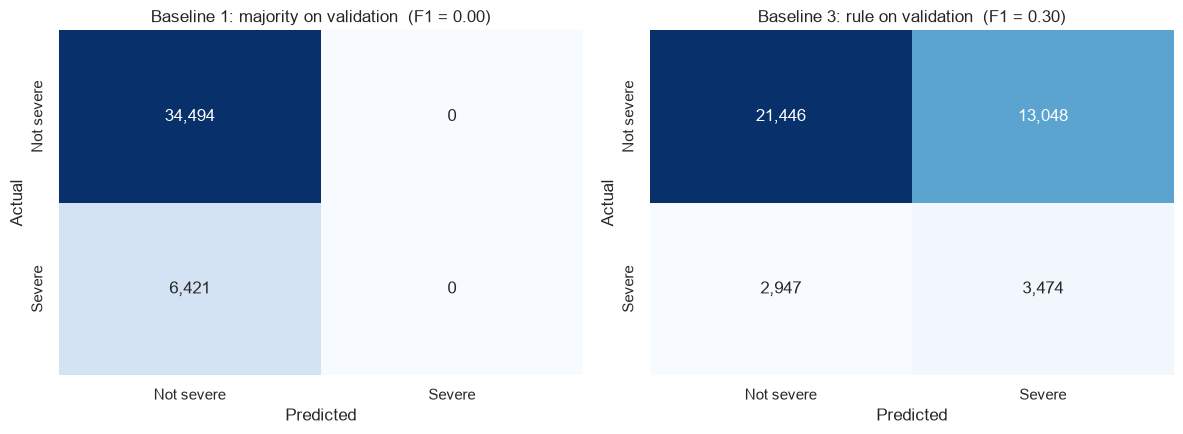

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, pred) in zip(axes, [("Baseline 1: majority", majority.predict(X_val)),
                                   ("Baseline 3: rule", baseline_3_rule(X_val))]):
    cm = confusion_matrix(y_val, pred)
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Not severe", "Severe"], yticklabels=["Not severe", "Severe"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(f"{name} on validation  (F1 = {f1_score(y_val, pred):.2f})")
plt.tight_layout()
plt.show()

- **Baseline 1** (majority class): 84.3% accuracy but **F1 = 0**, because it never finds a severe accident.
- **Baseline 3** (motorcycle OR pedestrian OR no car): finds **54% of the severe accidents** with a precision of 0.21, giving **F1 = 0.30** on the validation set. The training score is almost the same, so the rule is stable.

**F1 = 0.30 on the validation set is the score our models have to beat.**

### Baseline 4: Historical Scenario (Idea from Jishnu)

Jishnu (`02_jishnu_modeling.ipynb`) proposed a stronger baseline than our rules: a **lookup table of similar past accidents**. It is still simple and transparent, and it uses no post-accident information, so it is valid in Scenario C.

**How it works:**

1. Group the training accidents by **state × night × weekend × the exact combination of the six participants** (for example "car + bicycle, at night, at the weekend, in Saxony").
2. For each group, compute its severe share, **smoothed** towards the overall training rate:

   `probability = (severe accidents in the group + 100 × overall rate) / (accidents in the group + 100)`

   This is like adding 100 "average" accidents to every group: small groups move towards the overall rate, large groups keep their own rate.
3. A validation accident gets the probability of its group (the overall rate if the group never appeared in training).

Because it gives **probabilities**, we treat it like our models: the threshold comes from **out-of-fold predictions** (5-fold cross validation on the training set), and we score it on the validation set.

In [30]:
SCENARIO_COLUMNS = ["state", "is_night", "is_weekend"] + PARTICIPANTS
SMOOTHING = 100


def fit_scenario_table(features, target):
    """Smoothed severe share per scenario group, learned from the given (training) rows only."""
    prior = target.mean()
    groups = features[SCENARIO_COLUMNS].assign(is_severe=target.to_numpy()).groupby(SCENARIO_COLUMNS)["is_severe"]
    stats = groups.agg(["sum", "size"])
    return (stats["sum"] + SMOOTHING * prior) / (stats["size"] + SMOOTHING), prior


def predict_scenario_table(table, prior, features):
    """Look up each accident's group probability; unseen groups get the overall training rate."""
    keys = pd.MultiIndex.from_frame(features[SCENARIO_COLUMNS])
    return table.reindex(keys).fillna(prior).to_numpy()


# Out-of-fold probabilities on the training set, to choose the threshold without the validation set
oof_b4 = np.zeros(len(y_train))
for fit_rows, held_out_rows in CV.split(X_train, y_train):
    table, prior = fit_scenario_table(X_train.iloc[fit_rows], y_train.iloc[fit_rows])
    oof_b4[held_out_rows] = predict_scenario_table(table, prior, X_train.iloc[held_out_rows])
threshold_b4, cv_f1_b4 = best_f1_threshold(y_train, oof_b4)

# Final table from all training rows, applied to the validation set
table_b4, prior_b4 = fit_scenario_table(X_train, y_train)
p_val_b4 = predict_scenario_table(table_b4, prior_b4, X_val)
flags_b4 = (p_val_b4 >= threshold_b4).astype(int)

unseen = ~pd.MultiIndex.from_frame(X_val[SCENARIO_COLUMNS]).isin(table_b4.index)
print(f"Scenario groups in training: {len(table_b4):,}")
print(f"Validation accidents in unseen groups: {unseen.sum()} ({100 * unseen.mean():.2f}%)")
print(f"Threshold from cross validation: {threshold_b4:.3f}  (CV F1 {cv_f1_b4:.3f})")

Scenario groups in training: 1,327
Validation accidents in unseen groups: 44 (0.11%)
Threshold from cross validation: 0.151  (CV F1 0.314)


In [31]:
baseline_comparison = pd.DataFrame([
    {"model": "Baseline 1: majority class", "val PR-AUC": np.nan,
     "val precision": 0.0, "val recall": recall_score(y_val, majority.predict(X_val)),
     "val F1": f1_score(y_val, majority.predict(X_val))},
    {"model": "Baseline 3: rule without leakage", "val PR-AUC": np.nan,
     "val precision": precision_score(y_val, baseline_3_rule(X_val)),
     "val recall": recall_score(y_val, baseline_3_rule(X_val)),
     "val F1": f1_score(y_val, baseline_3_rule(X_val))},
    {"model": "Baseline 4: historical scenario", "val PR-AUC": average_precision_score(y_val, p_val_b4),
     "val precision": precision_score(y_val, flags_b4), "val recall": recall_score(y_val, flags_b4),
     "val F1": f1_score(y_val, flags_b4)},
]).set_index("model")
baseline_3_f1 = baseline_comparison.loc["Baseline 3: rule without leakage", "val F1"]
baseline_4_f1 = baseline_comparison.loc["Baseline 4: historical scenario", "val F1"]
baseline_comparison.round(3)

,val PR-AUC,val precision,val recall,val F1
model,,,,
Baseline 1: majority class,NaN,0.000,0.000,0.000
Baseline 3: rule without leakage,NaN,0.210,0.541,0.303
Baseline 4: historical scenario,0.229,0.213,0.600,0.315


The lookup table has **1,327 scenario groups**; only 44 validation accidents (0.11%) fall into a group never seen in training. With its cross-validated threshold (0.151), Baseline 4 reaches **F1 = 0.315** on the validation set (precision 0.213, recall 0.600) and a PR-AUC of 0.229.

### Baselines Summary

| Baseline | Validation F1 | Comment |
|---|---|---|
| 1: majority class | 0.000 | Never finds a severe accident |
| 3: rule without leakage | 0.303 | Motorcycle OR pedestrian OR no car |
| 4: historical scenario | **0.315** | The **strongest baseline**: state, night, weekend and participants combined |

Baseline 4 beats Baseline 3 by 0.012, because it combines the participants with **where** and **when** the accident happens. It is the hardest baseline for our models to beat, so we report the gain over **both** Baseline 3 and Baseline 4 from now on.

## 12. Learning from Zina's Models (`zb03.ipynb`)

Zina already trained three model types for Scenario C on the same data and split. Her best model (tuned gradient boosting with population density) reached **F1 = 0.338 on the test set**, compared with 0.317 for Scenario C without density.

**What we take over:**

- The careful column check: every column is either a feature or excluded with a reason (leakage, post-accident, ID, duplicate).
- **Population density on a log scale** (`log_pop_density`): by far her most important feature in the permutation importance.
- Pipelines (`make_pipeline` + `ColumnTransformer`), so the preprocessing is fitted on the training data only.
- Logistic regression, random forest and gradient boosting as the three model types, with **PR-AUC** to rank models and **F1** at a chosen threshold.
- The test set used only once, at the very end.

**What we try to improve:**

| Topic | In `zb03.ipynb` | What we do here |
|---|---|---|
| Decision threshold | Chosen on the model's predictions for its **own training data**. These are too optimistic, especially for random forest (it flagged only 29.7% of the validation accidents). | Chosen on **out-of-fold predictions** from 5-fold cross validation on the training set: every accident is predicted by a model that never saw it. |
| Features | Population density only | Also **urbanisation**, **municipality population**, **state age shares**, **`is_night`**, and **target-encoded districts and municipalities** (their severe share ranges from 3.8% to 35.5%) |
| Comparison | One set of features per model type | Every model type on **three feature sets**, so we see what each feature group adds |
| Split loading | Reads the ID column `UIDENTSTLAE`, which no longer exists in Tiziano's new split files | Reads `accident_id` |

**Expectations:** the features only carry weak signals (no single feature separates severe from slight accidents), so we expect small improvements, not a jump. Differences of 0.005 in F1 between models are within noise.

## 13. Modelling: Three Models on Three Feature Sets

### Feature Sets

| Set | Features | Idea |
|---|---|---|
| **A: Scenario C base** | state, light, road, 6 participants, `is_weekend`, cyclic hour and month, `n_participant_types`, coordinates | Same as Zina's "Szenario C" |
| **B: + density (Zina)** | A + `log_density` | Same as Zina's "Szenario C + population" |
| **C: + all team features** | All 28 features from this notebook: B + urbanisation, municipality population, state age shares, `is_night`, `vulnerable`, `single_type`, `vulnerable_vs_vehicle`, target-encoded `district` and `municipality` | Everything we built so far |

In [32]:
BASE_NUMERIC = ["hour_sin", "hour_cos", "month_sin", "month_cos", "n_participant_types", "longitude", "latitude"]

FEATURE_SETS = {
    "A: Scenario C base": {
        "nominal": ["state"], "ordinal": ["light_code", "road_code"],
        "binary": PARTICIPANTS + ["is_weekend"], "numeric": BASE_NUMERIC, "high_cardinality": [],
    },
    "B: + density (Zina)": {
        "nominal": ["state"], "ordinal": ["light_code", "road_code"],
        "binary": PARTICIPANTS + ["is_weekend"], "numeric": BASE_NUMERIC + ["log_density"],
        "high_cardinality": [],
    },
    "C: + all team features": {
        "nominal": NOMINAL, "ordinal": ORDINAL, "binary": BINARY, "numeric": NUMERIC,
        "high_cardinality": HIGH_CARDINALITY,
    },
}


def set_columns(feature_set):
    """All feature columns of a feature set."""
    return sum(feature_set.values(), [])


def make_set_preprocessor(feature_set):
    """Fresh, unfitted preprocessing for one feature set (fitted later on training data only)."""
    steps = [
        ("onehot", OneHotEncoder(handle_unknown="ignore"), feature_set["nominal"]),
        ("numeric", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), feature_set["numeric"]),
        ("ordinal", SimpleImputer(strategy="most_frequent"), feature_set["ordinal"]),
        ("binary", "passthrough", feature_set["binary"]),
    ]
    if feature_set["high_cardinality"]:
        steps.append(("target_encoding", TargetEncoder(
            target_type="binary", cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
        ), feature_set["high_cardinality"]))
    return ColumnTransformer(steps, verbose_feature_names_out=False)


for name, feature_set in FEATURE_SETS.items():
    print(f"{name:26s} {len(set_columns(feature_set)):2d} features")

A: Scenario C base         17 features
B: + density (Zina)        18 features
C: + all team features     28 features


### The Three Models

All three use their default class weights. The class imbalance is handled by the **decision threshold**: instead of 0.5, we pick the threshold with the best F1.

| Model | Settings | Why |
|---|---|---|
| Logistic regression | `max_iter=2000` | Simple, fast, interpretable; a linear model on the prepared features |
| Random forest | 300 trees, `min_samples_leaf=50`, `max_features="sqrt"` | Learns interactions (for example motorcycle on a rural road); same settings as Zina |
| Gradient boosting | `HistGradientBoostingClassifier`, learning rate 0.05, up to 500 iterations with early stopping, `min_samples_leaf=100` | Usually the strongest model on tabular data; same settings as Zina |

In [33]:
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

MODELS = {
    "Logistic regression": LogisticRegression(max_iter=2000),
    "Random forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=50, max_features="sqrt", n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient boosting": HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=500, max_leaf_nodes=31, min_samples_leaf=100,
        early_stopping=True, validation_fraction=0.1, random_state=RANDOM_STATE),
}

### Threshold from Cross Validation

For each model and feature set:

1. **5-fold cross validation on the training set** with `cross_val_predict`: every training accident gets a predicted probability from a model that **did not see it** (out-of-fold prediction). The whole pipeline, including target encoding and scaling, is refitted in every fold.
2. From these out-of-fold probabilities we take the **threshold with the best F1**, and we also report the cross-validated PR-AUC and F1.
3. We refit the pipeline on the **full training set**, predict the **validation set**, and apply the threshold from step 2. The validation set is not used to choose anything, so its scores are an honest comparison.

In [34]:
model_rows, fitted_models, val_probabilities = [], {}, {}
for set_name, feature_set in FEATURE_SETS.items():
    columns = set_columns(feature_set)
    for model_name, model in MODELS.items():
        start = time.time()
        pipeline = make_pipeline(make_set_preprocessor(feature_set), clone(model))

        oof = cross_val_predict(pipeline, X_train[columns], y_train, cv=CV, method="predict_proba")[:, 1]
        threshold, cv_f1 = best_f1_threshold(y_train, oof)

        pipeline.fit(X_train[columns], y_train)
        p_val = pipeline.predict_proba(X_val[columns])[:, 1]
        flags = (p_val >= threshold).astype(int)

        fitted_models[(set_name, model_name)] = pipeline
        val_probabilities[(set_name, model_name)] = p_val
        model_rows.append({
            "feature set": set_name, "model": model_name,
            "CV PR-AUC": average_precision_score(y_train, oof), "CV F1": cv_f1, "threshold": threshold,
            "val PR-AUC": average_precision_score(y_val, p_val), "val ROC-AUC": roc_auc_score(y_val, p_val),
            "val % flagged": 100 * flags.mean(), "val precision": precision_score(y_val, flags),
            "val recall": recall_score(y_val, flags), "val F1": f1_score(y_val, flags),
        })
        print(f"{set_name:26s} {model_name:20s} val F1 {model_rows[-1]['val F1']:.3f}  ({time.time() - start:.0f} s)")

model_results = pd.DataFrame(model_rows).set_index(["feature set", "model"])
model_results.round(3)

A: Scenario C base         Logistic regression  val F1 0.317  (7 s)


A: Scenario C base         Random forest        val F1 0.328  (185 s)


A: Scenario C base         Gradient boosting    val F1 0.332  (56 s)


B: + density (Zina)        Logistic regression  val F1 0.332  (6 s)


B: + density (Zina)        Random forest        val F1 0.342  (176 s)


B: + density (Zina)        Gradient boosting    val F1 0.341  (38 s)


C: + all team features     Logistic regression  val F1 0.335  (18 s)


C: + all team features     Random forest        val F1 0.340  (226 s)


C: + all team features     Gradient boosting    val F1 0.339  (47 s)


CV PR-AUC  CV F1  threshold  \
feature set            model                                              
A: Scenario C base     Logistic regression      0.229  0.312      0.149   
                       Random forest            0.247  0.324      0.163   
                       Gradient boosting        0.253  0.328      0.160   
B: + density (Zina)    Logistic regression      0.253  0.327      0.156   
                       Random forest            0.263  0.335      0.162   
                       Gradient boosting        0.265  0.338      0.164   
C: + all team features Logistic regression      0.260  0.333      0.163   
                       Random forest            0.264  0.338      0.171   
                       Gradient boosting        0.267  0.339      0.169   

                                            val PR-AUC  val ROC-AUC  \
feature set            model                                          
A: Scenario C base     Logistic regression       0.232        0.629   
                       Random forest             0.252        0.648   
                       Gradient boosting         0.256        0.654   
B: + density (Zina)    Logistic regression       0.260        0.660   
                       Random forest             0.272        0.669   
                       Gradient boosting         0.272        0.670   
C: + all team features Logistic regression       0.264        0.665   
                       Random forest             0.274        0.670   
                       Gradient boosting         0.271        0.670   

                                            val % flagged  val precision  \
feature set            model                                               
A: Scenario C base     Logistic regression         45.631          0.213   
                       Random forest               40.408          0.227   
                       Gradient boosting           41.044          0.230   
B: + density (Zina)    Logistic regression         40.298          0.231   
                       Random forest               42.552          0.234   
                       Gradient boosting           39.404          0.239   
C: + all team features Logistic regression         36.925          0.239   
                       Random forest               38.336          0.239   
                       Gradient boosting           37.265          0.241   

                                            val recall  val F1  
feature set            model                                    
A: Scenario C base     Logistic regression       0.620   0.317  
                       Random forest             0.585   0.328  
                       Gradient boosting         0.600   0.332  
B: + density (Zina)    Logistic regression       0.592   0.332  
                       Random forest             0.634   0.342  
                       Gradient boosting         0.599   0.341  
C: + all team features Logistic regression       0.561   0.335  
                       Random forest             0.585   0.340  
                       Gradient boosting         0.572   0.339

**How to read the table:** the `CV` columns come from out-of-fold predictions on the training set, the `val` columns from the validation set with the threshold chosen in cross validation.

- **Cross validation and validation agree well:** for every model, `CV F1` and `val F1` differ by at most about 0.01. So the threshold chosen on out-of-fold predictions transfers well to new data.
- The thresholds are all between **0.15 and 0.17**, close to the base rate (0.157), and the models flag **37% to 46%** of the validation accidents. Zina's random forest, with its threshold chosen on its own training predictions, flagged only 29.7%.

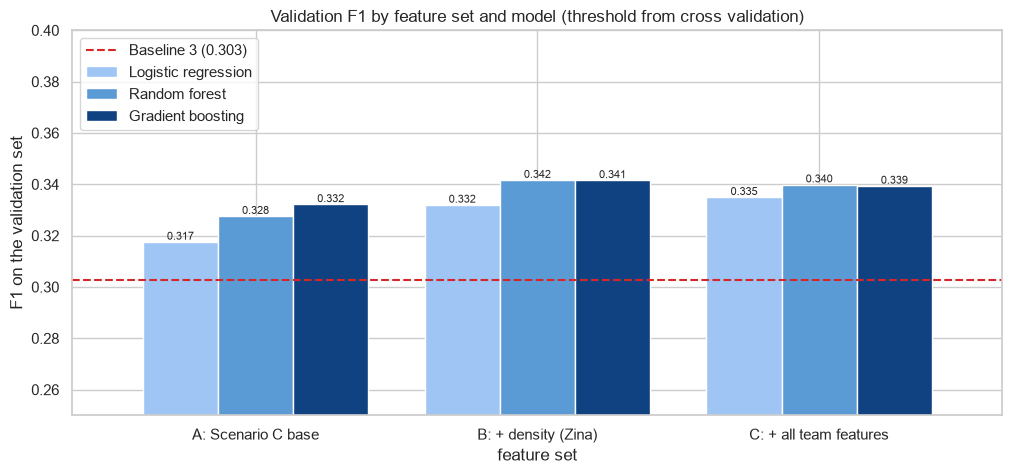

CV PR-AUC                                    \
model                  Gradient boosting Logistic regression Random forest   
feature set                                                                  
A: Scenario C base                 0.253               0.229         0.247   
B: + density (Zina)                0.265               0.253         0.263   
C: + all team features             0.267               0.260         0.264   

                              val PR-AUC                                    
model                  Gradient boosting Logistic regression Random forest  
feature set                                                                 
A: Scenario C base                 0.256               0.232         0.252  
B: + density (Zina)                0.272               0.260         0.272  
C: + all team features             0.271               0.264         0.274

In [35]:
BASELINE_3_VAL_F1 = f1_score(y_val, baseline_3_rule(X_val))

f1_table = model_results["val F1"].unstack("model")[list(MODELS)]
ax = f1_table.plot.bar(figsize=(12, 5), rot=0, color=["#9ec5f4", "#5b9bd5", "#104281"], width=0.8)
ax.axhline(BASELINE_3_VAL_F1, color="tab:red", linestyle="--", label=f"Baseline 3 ({BASELINE_3_VAL_F1:.3f})")
ax.set_ylim(0.25, max(0.40, f1_table.to_numpy().max() + 0.02))
ax.set_ylabel("F1 on the validation set")
ax.set_title("Validation F1 by feature set and model (threshold from cross validation)")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8)
ax.legend(loc="upper left")
plt.show()

model_results[["CV PR-AUC", "val PR-AUC"]].unstack("model").round(3)

- **Every model beats Baseline 3** (F1 = 0.303), by up to **0.04**.
- **Population density is the big step:** from set A to set B, F1 rises by **0.010 to 0.015** for all three models, and validation PR-AUC by **0.016 to 0.028**. This confirms Zina's result.
- **Our extra features (set C) add little for the tree models:** random forest 0.342 → 0.340, gradient boosting 0.341 → 0.339, which is within noise. Urbanisation, municipality population and the district keys mostly repeat what density already tells the trees. **Logistic regression does profit** (0.332 → 0.335, PR-AUC 0.260 → 0.264), because it cannot build such combinations by itself.
- **Trees beat logistic regression** on every feature set, but the gap shrinks with better features (A: 0.317 vs 0.332, C: 0.335 vs 0.340).
- **Random forest and gradient boosting are tied:** their F1 differs by at most 0.004. Gradient boosting is **3 to 5 times faster** (30 to 46 s versus 140 to 187 s for the full cross validation).

### The Best Model on the Validation Set

Best model: ('B: + density (Zina)', 'Random forest')  threshold 0.162


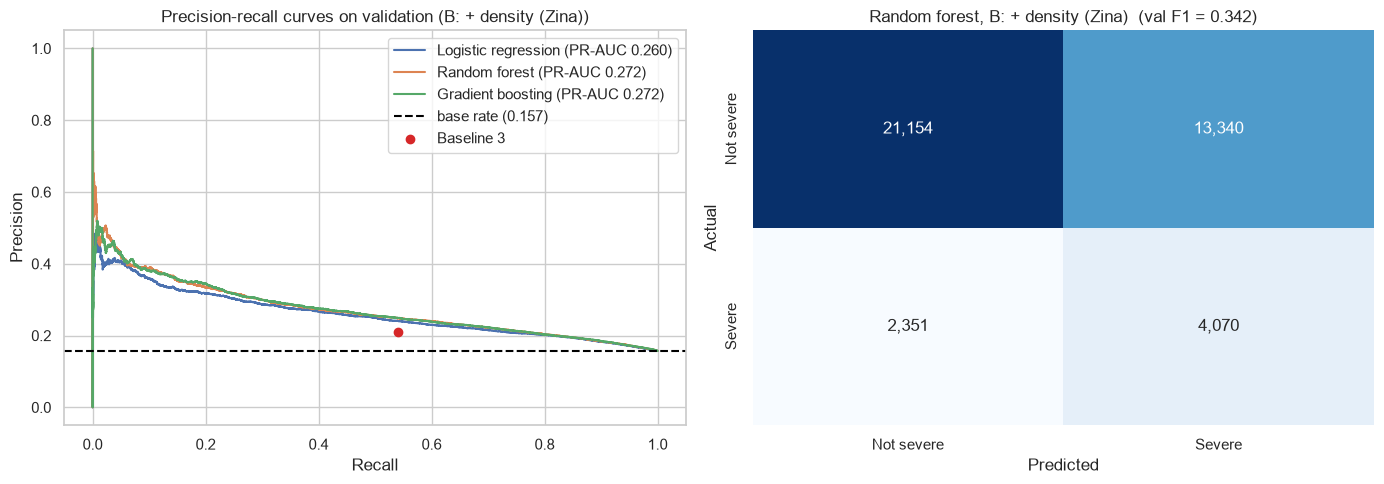

In [36]:
best_key = model_results["val F1"].idxmax()
best_model = fitted_models[best_key]
best_threshold = model_results.loc[best_key, "threshold"]
print("Best model:", best_key, " threshold %.3f" % best_threshold)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Precision-recall curves of the three models on the best feature set
for model_name in MODELS:
    key = (best_key[0], model_name)
    precision, recall, _ = precision_recall_curve(y_val, val_probabilities[key])
    axes[0].plot(recall, precision, label=f"{model_name} (PR-AUC {model_results.loc[key, 'val PR-AUC']:.3f})")
axes[0].axhline(y_val.mean(), color="black", linestyle="--", label=f"base rate ({y_val.mean():.3f})")
b3 = baseline_3_rule(X_val)
axes[0].scatter(recall_score(y_val, b3), precision_score(y_val, b3), color="tab:red", zorder=5,
                label="Baseline 3")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].set_title(f"Precision-recall curves on validation ({best_key[0]})")
axes[0].legend()

best_flags = (val_probabilities[best_key] >= best_threshold).astype(int)
sns.heatmap(confusion_matrix(y_val, best_flags), annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[1],
            xticklabels=["Not severe", "Severe"], yticklabels=["Not severe", "Severe"])
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")
axes[1].set_title(f"{best_key[1]}, {best_key[0]}  (val F1 = {f1_score(y_val, best_flags):.3f})")
plt.tight_layout()
plt.show()

The best validation F1 is the **random forest on set B** (F1 = **0.342**: precision 0.234, recall 0.634, 42.6% of accidents flagged). It finds about **63% of the severe accidents**, while about 1 in 4 flagged accidents is really severe.

In the precision-recall curves, random forest and gradient boosting lie almost on top of each other, and both lie above logistic regression over the whole range. Baseline 3 (red dot) lies below all three curves: at the same recall, the models are more precise.

⚠️ Choosing the best of 9 models on the validation set makes its score slightly optimistic. With differences this small, the honest conclusion is: **random forest and gradient boosting on set B or C are equally good, at F1 ≈ 0.34**.

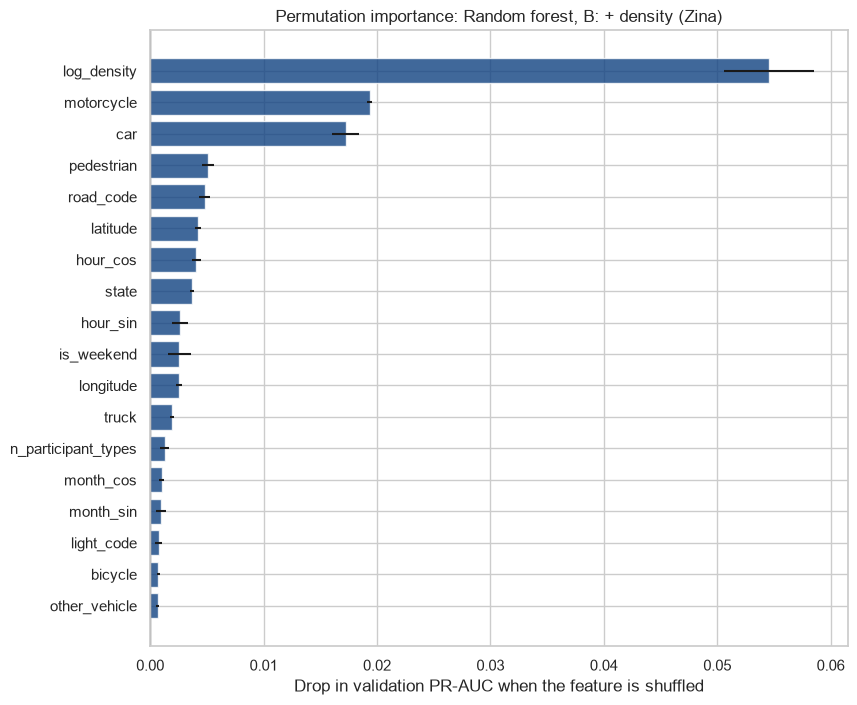

,feature,PR-AUC drop,std
17,log_density,0.0546,0.0040
6,motorcycle,0.0193,0.0002
4,car,0.0172,0.0012
5,pedestrian,0.0051,0.0005
2,road_code,0.0048,0.0005
16,latitude,0.0042,0.0003
11,hour_cos,0.0041,0.0004
0,state,0.0037,0.0002
10,hour_sin,0.0027,0.0007
9,is_weekend,0.0026,0.0010


In [37]:
from sklearn.inspection import permutation_importance

best_columns = set_columns(FEATURE_SETS[best_key[0]])
permutation = permutation_importance(best_model, X_val[best_columns], y_val, scoring="average_precision",
                                     n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.DataFrame({
    "feature": best_columns,
    "PR-AUC drop": permutation.importances_mean,
    "std": permutation.importances_std,
}).sort_values("PR-AUC drop")

plt.figure(figsize=(9, 8))
plt.barh(importance["feature"], importance["PR-AUC drop"], xerr=importance["std"], color="#104281", alpha=0.8)
plt.axvline(0, color="grey", linewidth=1)
plt.xlabel("Drop in validation PR-AUC when the feature is shuffled")
plt.title(f"Permutation importance: {best_key[1]}, {best_key[0]}")
plt.show()

importance.sort_values("PR-AUC drop", ascending=False).head(10).round(4)

**Population density** is by far the most important feature (PR-AUC drops by **0.055** when it is shuffled), followed by **motorcycle** (0.019) and **car** (0.017). Everything else adds only small amounts. This matches Zina's permutation importance and the EDA: **where** the accident happens (rural or urban) and **who** is involved matter most.

Correlated features share their importance: `latitude`, `longitude` and `state` all describe the location, so each of them looks less important than the location as a whole.

### Modelling Summary

| Result | Value |
|---|---|
| Baseline 3 (rule, no leakage) | F1 = 0.303 |
| Best model on validation | Random forest, set B: **F1 = 0.342** (PR-AUC 0.272) |
| Gain from population density (A → B) | +0.010 to +0.015 F1 |
| Gain from our extra features (B → C) | about 0 for trees, +0.003 for logistic regression |

**Recommendation for the next iteration:** continue with **gradient boosting**. It is tied with random forest on F1, has the best cross-validated PR-AUC (0.267 on set C), and is much faster, which matters for tuning. Use set **B** (simple) or **C** (slightly better PR-AUC) and decide with cross validation after tuning.

## 14. Hyperparameter Tuning of the Three Models

So far all models used fixed settings (scikit-learn defaults for logistic regression, Zina's settings for the trees). Now we **tune every model** to find its best settings, and then compare the tuned models with **our baselines**.

### How We Tune

1. **Feature set C** (all team features): it has the best cross-validated PR-AUC for all three models (see the table above). We choose it with cross validation, not with the validation set.
2. **`RandomizedSearchCV` on the training set only:** it tries random combinations from the search space below and scores each one with cross validation. The whole pipeline (target encoding, scaling, model) is refitted in every fold, so there is no leakage.
3. **Scoring: PR-AUC** (`average_precision`). It measures how well a model ranks severe accidents above slight ones, independent of the threshold. The threshold is chosen afterwards.
4. **Threshold from out-of-fold predictions** of the tuned model (5-fold cross validation), exactly as before.
5. **Comparison on the validation set**, against Baseline 1 and Baseline 3. The test set stays untouched.

### Search Spaces

| Model | Hyperparameter | Values tried | What it controls |
|---|---|---|---|
| Logistic regression | `C` | 0.001 to 100 (log scale) | Regularisation strength: small `C` = simpler model |
| | `class_weight` | none, balanced | Whether severe accidents get more weight in training |
| Random forest | `min_samples_leaf` | 5 to 200 | Minimum accidents per leaf: larger = smoother, less overfitting |
| | `max_features` | sqrt, 30%, 50% of the features | How many features each split may look at |
| | `max_depth` | none, 12, 20 | Maximum tree depth |
| | `max_samples` | 30%, 60%, 100% of the rows | Rows per tree (smaller = faster and more diverse trees) |
| | `class_weight` | none, balanced_subsample | Extra weight for severe accidents |
| Gradient boosting | `learning_rate` | 0.02 to 0.2 (log scale) | Step size of each new tree |
| | `max_leaf_nodes` | 15 to 63 | Size of each tree |
| | `min_samples_leaf` | 20 to 500 | Minimum accidents per leaf |
| | `l2_regularization` | 0.001 to 10 (log scale) | Penalty against extreme leaf values |
| | `max_features` | 40% to 100% | Share of features each split may use |
| | `class_weight` | none, balanced | Extra weight for severe accidents |

**Budget:** logistic regression and gradient boosting are fast, so they get **5-fold** cross validation with **15** and **40** trials. Random forest is slow on 190,000 accidents, so it gets **3-fold** cross validation, **15** trials and 200 trees. The tuning takes a while to run; the time per model is printed below.

In [38]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV

TUNING_SET_NAME = "C: + all team features"
tuning_columns = set_columns(FEATURE_SETS[TUNING_SET_NAME])

SEARCHES = {
    "Logistic regression": {
        "estimator": LogisticRegression(max_iter=3000),
        "params": {
            "logisticregression__C": loguniform(1e-3, 1e2),
            "logisticregression__class_weight": [None, "balanced"],
        },
        "n_iter": 15, "folds": 5, "n_jobs": -1,
    },
    "Random forest": {
        "estimator": RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE),
        "params": {
            "randomforestclassifier__min_samples_leaf": randint(5, 201),
            "randomforestclassifier__max_features": ["sqrt", 0.3, 0.5],
            "randomforestclassifier__max_depth": [None, 12, 20],
            "randomforestclassifier__max_samples": [0.3, 0.6, None],
            "randomforestclassifier__class_weight": [None, "balanced_subsample"],
        },
        "n_iter": 15, "folds": 3, "n_jobs": 1,   # the forest itself already uses all cores
    },
    "Gradient boosting": {
        "estimator": HistGradientBoostingClassifier(
            max_iter=1000, early_stopping=True, validation_fraction=0.1, n_iter_no_change=20,
            random_state=RANDOM_STATE),
        "params": {
            "histgradientboostingclassifier__learning_rate": loguniform(0.02, 0.2),
            "histgradientboostingclassifier__max_leaf_nodes": randint(15, 64),
            "histgradientboostingclassifier__min_samples_leaf": randint(20, 501),
            "histgradientboostingclassifier__l2_regularization": loguniform(1e-3, 10),
            "histgradientboostingclassifier__max_features": uniform(0.4, 0.6),
            "histgradientboostingclassifier__class_weight": [None, "balanced"],
        },
        "n_iter": 40, "folds": 5, "n_jobs": -1,
    },
}

searches = {}
for model_name, spec in SEARCHES.items():
    start = time.time()
    search = RandomizedSearchCV(
        make_pipeline(make_set_preprocessor(FEATURE_SETS[TUNING_SET_NAME]), spec["estimator"]),
        param_distributions=spec["params"], n_iter=spec["n_iter"], scoring="average_precision",
        cv=StratifiedKFold(n_splits=spec["folds"], shuffle=True, random_state=RANDOM_STATE),
        n_jobs=spec["n_jobs"], random_state=RANDOM_STATE, refit=True,
    )
    search.fit(X_train[tuning_columns], y_train)
    searches[model_name] = search
    best = {k.split("__")[1]: (round(v, 4) if isinstance(v, float) else v) for k, v in search.best_params_.items()}
    print(f"{model_name}: best CV PR-AUC {search.best_score_:.4f} ({time.time() - start:.0f} s)")
    print("   ", best)

Logistic regression: best CV PR-AUC 0.2598 (72 s)
    {'C': np.float64(1.1436), 'class_weight': None}


Random forest: best CV PR-AUC 0.2640 (1240 s)
    {'class_weight': None, 'max_depth': 12, 'max_features': 0.3, 'max_samples': 0.6, 'min_samples_leaf': 13}


Gradient boosting: best CV PR-AUC 0.2690 (1522 s)
    {'class_weight': 'balanced', 'l2_regularization': np.float64(0.0441), 'learning_rate': np.float64(0.0216), 'max_features': np.float64(0.607), 'max_leaf_nodes': 15, 'min_samples_leaf': 422}


| Model | Best cross-validated PR-AUC | Best settings | Time |
|---|---|---|---|
| Logistic regression | 0.260 | `C` = 1.14 (close to the default 1.0), no class weights | about 1 minute |
| Random forest | 0.264 | `max_depth` 12, `max_features` 30%, `max_samples` 60%, `min_samples_leaf` 13, no class weights | about 21 minutes |
| Gradient boosting | **0.269** | `learning_rate` 0.022, `max_leaf_nodes` 15, `min_samples_leaf` 422, `l2_regularization` 0.044, `max_features` 61%, **`class_weight` balanced** | about 28 minutes |

- **Gradient boosting** is again the best model in cross validation. Its best settings are **slow and cautious**: a small learning rate, small trees and large leaves (at least 422 accidents per leaf). With such weak signals, simple trees that average over many accidents generalise best.
- **Logistic regression** barely changes: the default `C` was already near the optimum.
- **Random forest** prefers shallower trees (depth 12) built on 60% of the rows and 30% of the features.
- Compared with the untuned models, the gains in cross-validated PR-AUC are small (for example 0.267 → 0.269 for gradient boosting).

### Thresholds and Validation Scores of the Tuned Models

For each tuned model we take the out-of-fold predictions (5-fold cross validation on the training set), choose the threshold with the best F1, and apply it to the validation set. `best_estimator_` was already refitted on the full training set by `RandomizedSearchCV`.

In [39]:
tuned_rows, tuned_probabilities = [], {}
for model_name, search in searches.items():
    start = time.time()
    oof = cross_val_predict(clone(search.best_estimator_), X_train[tuning_columns], y_train, cv=CV,
                            method="predict_proba", n_jobs=SEARCHES[model_name]["n_jobs"])[:, 1]
    threshold, cv_f1 = best_f1_threshold(y_train, oof)
    p_val = search.best_estimator_.predict_proba(X_val[tuning_columns])[:, 1]
    flags = (p_val >= threshold).astype(int)
    tuned_probabilities[model_name] = (p_val, threshold)
    tuned_rows.append({
        "model": f"{model_name} (tuned)",
        "CV PR-AUC": average_precision_score(y_train, oof), "CV F1": cv_f1, "threshold": threshold,
        "val PR-AUC": average_precision_score(y_val, p_val), "val ROC-AUC": roc_auc_score(y_val, p_val),
        "val % flagged": 100 * flags.mean(), "val precision": precision_score(y_val, flags),
        "val recall": recall_score(y_val, flags), "val F1": f1_score(y_val, flags),
    })
    print(f"{model_name:20s} val F1 {tuned_rows[-1]['val F1']:.3f}  ({time.time() - start:.0f} s)")

tuned_results = pd.DataFrame(tuned_rows).set_index("model")
tuned_results.round(3)

Logistic regression  val F1 0.336  (6 s)


Random forest        val F1 0.341  (203 s)


Gradient boosting    val F1 0.341  (165 s)


,CV PR-AUC,CV F1,threshold,val PR-AUC,val ROC-AUC,val % flagged,val precision,val recall,val F1
model,,,,,,,,,
Logistic regression (tuned),0.259,0.333,0.160,0.264,0.665,38.651,0.236,0.581,0.336
Random forest (tuned),0.264,0.337,0.164,0.272,0.669,40.039,0.237,0.606,0.341
Gradient boosting (tuned),0.268,0.339,0.529,0.271,0.671,35.058,0.247,0.552,0.341


- All three tuned models score **val F1 = 0.336 to 0.341**, almost the same as before tuning (0.335 to 0.340).
- The threshold of the tuned gradient boosting is **0.529** instead of about 0.17. This is not a mistake: with `class_weight="balanced"`, the model gives severe accidents more weight in training, which pushes **all predicted probabilities up**. The ranking and the F1 at the best threshold are what count, but these probabilities can no longer be read as real risks (see the calibration check in section 17).
- Again, the cross-validated F1 and the validation F1 agree closely (0.333 to 0.339 versus 0.336 to 0.341), so the cross-validated thresholds transfer well.

### Tuned Models versus Our Baselines

This is the comparison that counts: how much do our tuned Scenario C models beat the simple baselines (1, 3 and 4) on the validation set?

In [40]:
untuned_c = model_results.loc[TUNING_SET_NAME, ["val PR-AUC", "val precision", "val recall", "val F1"]]
untuned_c.index = [f"{m} (untuned)" for m in untuned_c.index]

final_comparison = pd.concat([
    baseline_comparison,
    untuned_c,
    tuned_results[["val PR-AUC", "val precision", "val recall", "val F1"]],
])
final_comparison["F1 gain over Baseline 3"] = final_comparison["val F1"] - baseline_3_f1
final_comparison["F1 gain over Baseline 4"] = final_comparison["val F1"] - baseline_4_f1
final_comparison["relative gain over Baseline 3 (%)"] = 100 * final_comparison["F1 gain over Baseline 3"] / baseline_3_f1
final_comparison.round(3)

,val PR-AUC,val precision,val recall,val F1,F1 gain over Baseline 3,F1 gain over Baseline 4,relative gain over Baseline 3 (%)
Baseline 1: majority class,NaN,0.000,0.000,0.000,-0.303,-0.315,-100.000
Baseline 3: rule without leakage,NaN,0.210,0.541,0.303,0.000,-0.012,0.000
Baseline 4: historical scenario,0.229,0.213,0.600,0.315,0.012,0.000,3.862
Logistic regression (untuned),0.264,0.239,0.561,0.335,0.032,0.020,10.586
Random forest (untuned),0.274,0.239,0.585,0.340,0.037,0.025,12.211
Gradient boosting (untuned),0.271,0.241,0.572,0.339,0.036,0.025,12.041
Logistic regression (tuned),0.264,0.236,0.581,0.336,0.033,0.021,10.788
Random forest (tuned),0.272,0.237,0.606,0.341,0.038,0.027,12.662
Gradient boosting (tuned),0.271,0.247,0.552,0.341,0.038,0.027,12.683


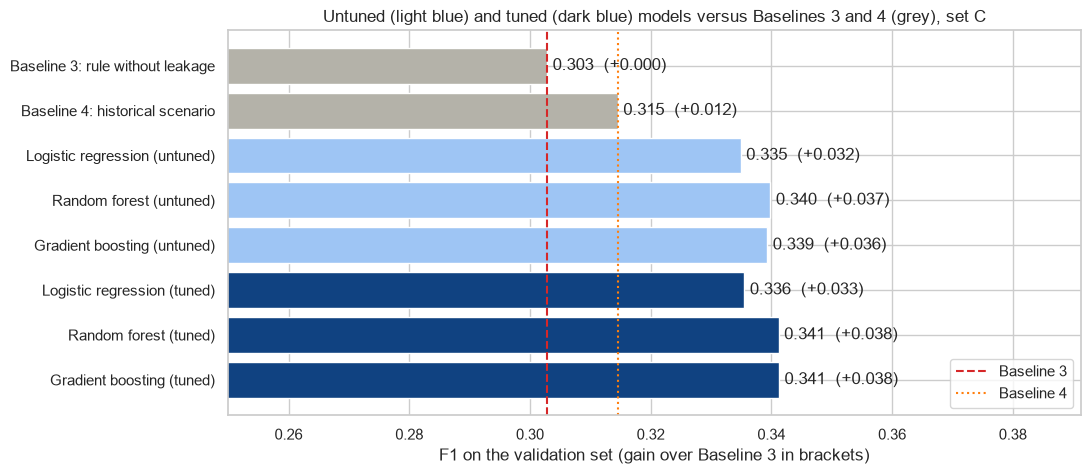

In [41]:
plot_data = final_comparison.drop(index="Baseline 1: majority class")
colors = ["#b4b2a9"] * 2 + ["#9ec5f4"] * 3 + ["#104281"] * 3

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.barh(plot_data.index, plot_data["val F1"], color=colors)
ax.bar_label(bars, labels=[f"{f1:.3f}  ({gain:+.3f})" for f1, gain in
                           zip(plot_data["val F1"], plot_data["F1 gain over Baseline 3"])], padding=4)
ax.axvline(baseline_3_f1, color="tab:red", linestyle="--", label="Baseline 3")
ax.axvline(baseline_4_f1, color="tab:orange", linestyle=":", label="Baseline 4")
ax.invert_yaxis()
ax.set_xlim(0.25, plot_data["val F1"].max() + 0.05)
ax.set_xlabel("F1 on the validation set (gain over Baseline 3 in brackets)")
ax.set_title("Untuned (light blue) and tuned (dark blue) models versus Baselines 3 and 4 (grey), set C")
ax.legend(loc="lower right")
plt.show()

- **Every model beats Baseline 3** (F1 0.303) by **0.032 to 0.038**, a **relative gain of 11% to 13%**.
- **Tuning adds very little:** at most +0.002 F1 (random forest 0.340 → 0.341, gradient boosting 0.339 → 0.341). The defaults and Zina's settings were already good; the limit is the information in the data, not the settings.
- **Random forest and gradient boosting are tied** at F1 = 0.341. Gradient boosting is more precise (0.247 versus 0.237), random forest finds more severe accidents (recall 0.606 versus 0.552).
- Against the stronger **Baseline 4** (historical scenario, F1 0.315), the tuned models gain **+0.021 to +0.027** F1.

Best tuned model: Gradient boosting  threshold 0.529


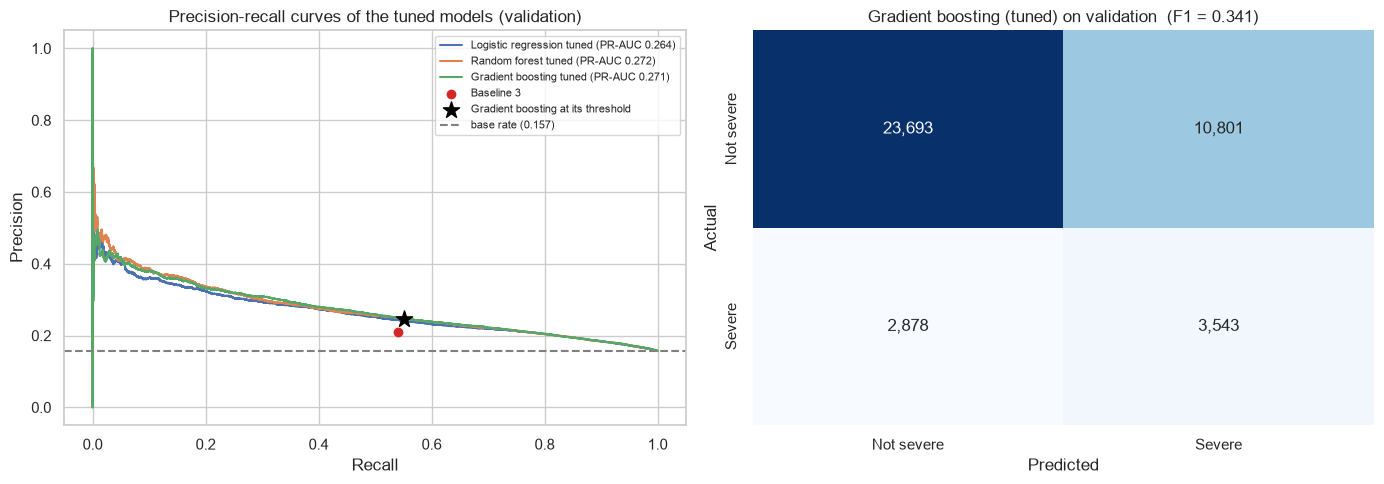

Baseline 3:  TP  3474  FP  13048  FN  2947
Best model:  TP  3543  FP  10801  FN  2878


In [42]:
best_tuned_name = tuned_results["val F1"].idxmax().replace(" (tuned)", "")
p_best, threshold_best = tuned_probabilities[best_tuned_name]
flags_best = (p_best >= threshold_best).astype(int)
print("Best tuned model:", best_tuned_name, " threshold %.3f" % threshold_best)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for model_name, (p_val, _) in tuned_probabilities.items():
    precision, recall, _ = precision_recall_curve(y_val, p_val)
    axes[0].plot(recall, precision, label=f"{model_name} tuned (PR-AUC {average_precision_score(y_val, p_val):.3f})")
b3 = baseline_3_rule(X_val)
axes[0].scatter(recall_score(y_val, b3), precision_score(y_val, b3), color="tab:red", zorder=5, label="Baseline 3")
axes[0].scatter(recall_score(y_val, flags_best), precision_score(y_val, flags_best), color="black", marker="*",
                s=150, zorder=5, label=f"{best_tuned_name} at its threshold")
axes[0].axhline(y_val.mean(), color="grey", linestyle="--", label=f"base rate ({y_val.mean():.3f})")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].set_title("Precision-recall curves of the tuned models (validation)")
axes[0].legend(fontsize=8)

sns.heatmap(confusion_matrix(y_val, flags_best), annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[1],
            xticklabels=["Not severe", "Severe"], yticklabels=["Not severe", "Severe"])
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")
axes[1].set_title(f"{best_tuned_name} (tuned) on validation  (F1 = {f1_score(y_val, flags_best):.3f})")
plt.tight_layout()
plt.show()

b3_cm = confusion_matrix(y_val, b3).ravel()
best_cm = confusion_matrix(y_val, flags_best).ravel()
print("Baseline 3:  TP %5d  FP %6d  FN %5d" % (b3_cm[3], b3_cm[1], b3_cm[2]))
print("Best model:  TP %5d  FP %6d  FN %5d" % (best_cm[3], best_cm[1], best_cm[2]))

The tuned **gradient boosting** has the best validation F1 (by a hair over random forest). Compared with Baseline 3 on the same 40,915 validation accidents:

| | Severe accidents found (TP) | False alarms (FP) | Severe accidents missed (FN) |
|---|---|---|---|
| Baseline 3 | 3,474 | 13,048 | 2,947 |
| **Tuned gradient boosting** | **3,543** | **10,801** | **2,878** |

The model finds **69 more severe accidents** and raises **2,247 fewer false alarms** (−17%) than the rule. Its curve lies above Baseline 3 over the whole recall range.

### Tuning Summary

| Result | Value |
|---|---|
| Baseline 3 (rule, no leakage) | F1 = 0.303 |
| Best tuned model on validation | Gradient boosting (tuned), set C: **F1 = 0.341**, PR-AUC 0.271 |
| Gain over Baseline 3 | **+0.038 F1 (+12.7%)**, 17% fewer false alarms |
| Gain from tuning | about +0.002 F1 |

**Conclusion:** tuning confirms that we are close to what these features allow. Further gains have to come from **better features**, which we test next with interaction features and an ablation study.

## 15. Ablation Study: Which Feature Groups Really Help?

So far we compared three fixed feature sets. Now we test the features **group by group**: we start from **all features** (set C + interactions) and **remove one group at a time**. If the score drops, the group helps; if it stays the same or rises, the group adds nothing (or only noise).

- **Model:** the **tuned gradient boosting** (best settings from the search above), because it is fast and among the best models.
- **Evaluation:** 5-fold cross validation on the **training set only** (PR-AUC per fold, and F1 at the best out-of-fold threshold). The validation set is **not** used to choose features.
- **Noise level:** we report the standard deviation of PR-AUC over the 5 folds. Differences smaller than that are not meaningful.

| Group | Columns |
|---|---|
| Urban-rural | `log_density`, `log_population`, `urbanisation_code` |
| Participants | six participant flags, `vulnerable`, `single_type`, `vulnerable_vs_vehicle`, `n_participant_types` |
| Time | cyclic hour and month, `is_weekend`, `is_night` |
| Conditions | `light_code`, `road_code` |
| Location | `state`, `longitude`, `latitude` |
| Region keys | target-encoded `district`, `municipality` |
| State age shares | `state_young_0_16_pct`, `state_senior_67_plus_pct` |
| Redundant `single_type` | `single_type` alone: it is almost the same as `n_participant_types` = 1 (correlation -0.99), so removing it should cost nothing |
| Interactions | the seven new flags |

In [43]:
FULL_SET = {
    "nominal": NOMINAL, "ordinal": ORDINAL, "binary": BINARY + INTERACTIONS,
    "numeric": NUMERIC, "high_cardinality": HIGH_CARDINALITY,
}
FEATURE_GROUPS = {
    "Urban-rural": ["log_density", "log_population", "urbanisation_code"],
    "Participants": PARTICIPANTS + ["vulnerable", "single_type", "vulnerable_vs_vehicle", "n_participant_types"],
    "Time": ["hour_sin", "hour_cos", "month_sin", "month_cos", "is_weekend", "is_night"],
    "Conditions": ["light_code", "road_code"],
    "Location": ["state", "longitude", "latitude"],
    "Region keys": ["district", "municipality"],
    "State age shares": ["state_young_0_16_pct", "state_senior_67_plus_pct"],
    "Redundant single_type": ["single_type"],
    "Interactions": INTERACTIONS,
}


def without(feature_set, columns):
    """Copy of a feature set without the given columns."""
    return {part: [c for c in cols if c not in columns] for part, cols in feature_set.items()}


tuned_gb = searches["Gradient boosting"].best_estimator_.named_steps["histgradientboostingclassifier"]
X_train_full, X_val_full = train[set_columns(FULL_SET)], val[set_columns(FULL_SET)]


def cv_evaluate(feature_set):
    """5-fold CV on the training set: PR-AUC per fold and F1 at the best out-of-fold threshold."""
    columns = set_columns(feature_set)
    oof, fold_ap = np.zeros(len(y_train)), []
    for fit_rows, held_out_rows in CV.split(X_train_full, y_train):
        model = make_pipeline(make_set_preprocessor(feature_set), clone(tuned_gb))
        model.fit(X_train_full.iloc[fit_rows][columns], y_train.iloc[fit_rows])
        oof[held_out_rows] = model.predict_proba(X_train_full.iloc[held_out_rows][columns])[:, 1]
        fold_ap.append(average_precision_score(y_train.iloc[held_out_rows], oof[held_out_rows]))
    threshold, f1 = best_f1_threshold(y_train, oof)
    return {"features": len(columns), "CV PR-AUC": np.mean(fold_ap), "PR-AUC std": np.std(fold_ap),
            "CV F1": f1, "threshold": threshold}


experiments = {"All features (C + interactions)": FULL_SET,
               "Set C (no interactions)": without(FULL_SET, INTERACTIONS)}
experiments.update({f"All minus {group}": without(FULL_SET, cols) for group, cols in FEATURE_GROUPS.items()
                    if group != "Interactions"})

ablation_rows = []
for name, feature_set in experiments.items():
    start = time.time()
    ablation_rows.append({"experiment": name, **cv_evaluate(feature_set)})
    print(f"{name:36s} CV PR-AUC {ablation_rows[-1]['CV PR-AUC']:.4f}  CV F1 {ablation_rows[-1]['CV F1']:.4f}"
          f"  ({time.time() - start:.0f} s)")

ablation = pd.DataFrame(ablation_rows).set_index("experiment")
full_ap = ablation.loc["All features (C + interactions)", "CV PR-AUC"]
full_f1 = ablation.loc["All features (C + interactions)", "CV F1"]
ablation["PR-AUC change"] = ablation["CV PR-AUC"] - full_ap
ablation["F1 change"] = ablation["CV F1"] - full_f1
ablation.round(4)

All features (C + interactions)      CV PR-AUC 0.2689  CV F1 0.3392  (235 s)


Set C (no interactions)              CV PR-AUC 0.2690  CV F1 0.3391  (226 s)


All minus Urban-rural                CV PR-AUC 0.2650  CV F1 0.3358  (226 s)


All minus Participants               CV PR-AUC 0.2574  CV F1 0.3271  (197 s)


All minus Time                       CV PR-AUC 0.2666  CV F1 0.3373  (221 s)


...

All minus Location                   CV PR-AUC 0.2682  CV F1 0.3389  (181 s)


All minus Region keys                CV PR-AUC 0.2685  CV F1 0.3389  (227 s)


All minus State age shares           CV PR-AUC 0.2693  CV F1 0.3400  (233 s)


All minus Redundant single_type      CV PR-AUC 0.2687  CV F1 0.3395  (231 s)


,features,CV PR-AUC,PR-AUC std,CV F1,threshold,PR-AUC change,F1 change
experiment,,,,,,,
All features (C + interactions),35,0.2689,0.0044,0.3392,0.5236,0.0000,0.0000
Set C (no interactions),28,0.2690,0.0048,0.3391,0.5289,0.0001,-0.0001
All minus Urban-rural,32,0.2650,0.0036,0.3358,0.5170,-0.0039,-0.0034
All minus Participants,25,0.2574,0.0034,0.3271,0.4984,-0.0115,-0.0121
All minus Time,29,0.2666,0.0041,0.3373,0.5134,-0.0023,-0.0019
All minus Conditions,33,0.2665,0.0053,0.3377,0.5118,-0.0024,-0.0015
All minus Location,32,0.2682,0.0047,0.3389,0.5250,-0.0007,-0.0003
All minus Region keys,33,0.2685,0.0040,0.3389,0.5115,-0.0003,-0.0003
All minus State age shares,33,0.2693,0.0045,0.3400,0.5267,0.0004,0.0008


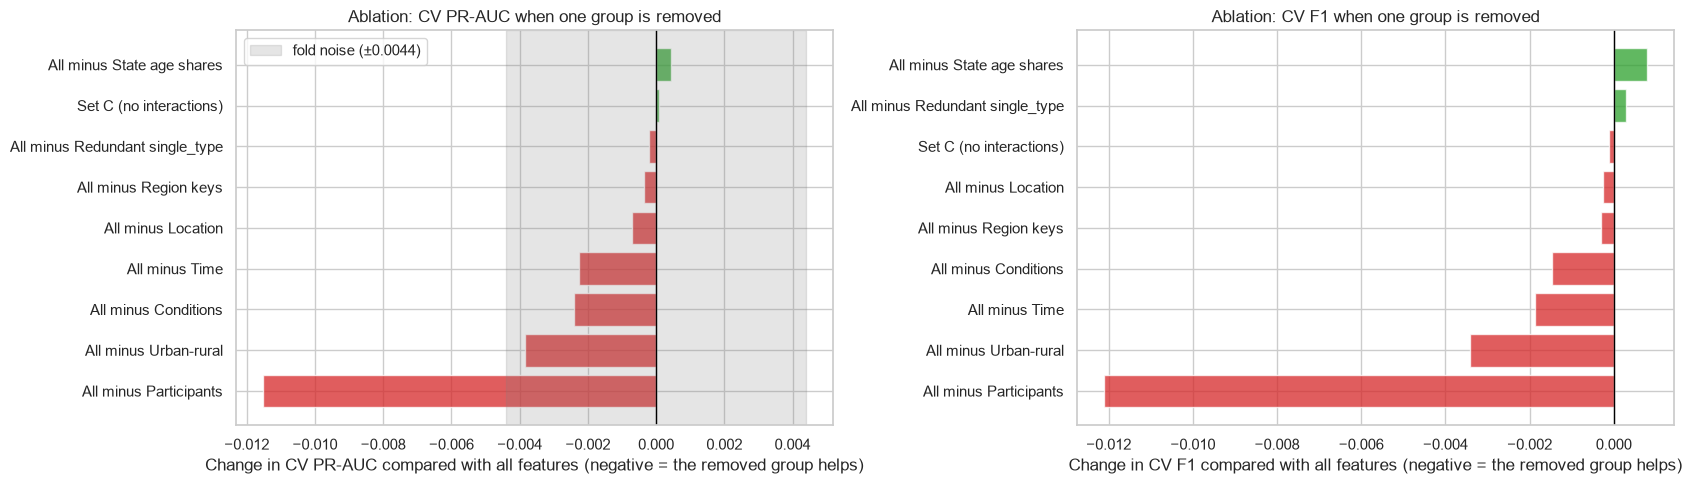

In [44]:
plot_ablation = ablation.drop(index="All features (C + interactions)").sort_values("PR-AUC change")
noise = ablation.loc["All features (C + interactions)", "PR-AUC std"]

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
for ax, column, label in [(axes[0], "PR-AUC change", "CV PR-AUC"), (axes[1], "F1 change", "CV F1")]:
    data = plot_ablation.sort_values(column)
    ax.barh(data.index, data[column], color=np.where(data[column] < 0, "tab:red", "tab:green"), alpha=0.75)
    ax.axvline(0, color="black", linewidth=1)
    if column == "PR-AUC change":
        ax.axvspan(-noise, noise, color="grey", alpha=0.2, label=f"fold noise (±{noise:.4f})")
        ax.legend()
    ax.set_xlabel(f"Change in {label} compared with all features (negative = the removed group helps)")
    ax.set_title(f"Ablation: {label} when one group is removed")
plt.tight_layout()
plt.show()

**Reading the result:** the fold-to-fold noise of PR-AUC is about **±0.004**, so only larger changes are meaningful.

| Group removed | PR-AUC change | Verdict |
|---|---|---|
| **Participants** | **−0.0115** | **By far the most important group** (F1 −0.012) |
| **Urban-rural** (density, population, urbanisation) | **−0.0039** | Clearly helps |
| Time | −0.0023 | Helps a little |
| Conditions (light, road) | −0.0024 | Helps a little |
| Location (state, coordinates) | −0.0007 | No measurable effect: the urban-rural features already describe the location |
| Region keys (districts, municipalities) | −0.0003 | No measurable effect |
| Redundant `single_type` | −0.0002 | No effect, **can be dropped**, as expected from its −0.99 correlation |
| **Interactions** (set C without them) | **+0.0001** | **No effect**: the tuned gradient boosting already finds these combinations by itself |
| **State age shares** | **+0.0004** | **No effect, slightly better without them** |

**Conclusions:**

- **Who is involved** and **how rural the place is** carry most of the signal. Time and conditions add a little.
- The **seven interaction flags do not help** the tree model, even though each of them marks a high-risk group. Gradient boosting builds such combinations automatically. They could still help a linear model.
- **Zina's state age shares** add nothing once the municipality-level urban-rural features are in the model, which confirms the warning from the EDA (16 values, mixed up with urban versus rural).
- Several groups (location, region keys, `single_type`) could be removed without loss, which would give a **simpler model** with the same score.

By our fixed rule (highest CV PR-AUC), the chosen feature set is **"All minus State age shares"** (33 features). Note that its advantage over the full set (+0.0004) is far below the noise, so this choice is effectively a tie.

### Final Model: Tuned Gradient Boosting on the Chosen Feature Set

**Selection rule (fixed before looking at the validation set):** we keep the experiment with the **highest cross-validated PR-AUC** in the ablation table. We then train the tuned gradient boosting on this feature set, take the threshold from out-of-fold predictions, and score it once on the validation set next to the tuned model on set C.

In [45]:
FINAL_SET_NAME = ablation["CV PR-AUC"].idxmax()
FINAL_SET = experiments[FINAL_SET_NAME]
print("Chosen feature set:", FINAL_SET_NAME)
final_columns = set_columns(FINAL_SET)

final_model = make_pipeline(make_set_preprocessor(FINAL_SET), clone(tuned_gb))
oof_final = cross_val_predict(final_model, X_train_full[final_columns], y_train, cv=CV, method="predict_proba")[:, 1]
threshold_final, cv_f1_final = best_f1_threshold(y_train, oof_final)
final_model.fit(X_train_full[final_columns], y_train)
p_val_final = final_model.predict_proba(X_val_full[final_columns])[:, 1]
flags_final = (p_val_final >= threshold_final).astype(int)

final_feature_row = pd.DataFrame([{
    "model": f"Gradient boosting (tuned), {FINAL_SET_NAME}",
    "val PR-AUC": average_precision_score(y_val, p_val_final),
    "val precision": precision_score(y_val, flags_final),
    "val recall": recall_score(y_val, flags_final),
    "val F1": f1_score(y_val, flags_final),
}]).set_index("model")
final_feature_comparison = pd.concat([
    final_comparison.loc[["Baseline 3: rule without leakage", "Baseline 4: historical scenario",
                                  "Gradient boosting (tuned)"],
                                 ["val PR-AUC", "val precision", "val recall", "val F1"]],
    final_feature_row,
])
final_feature_comparison["F1 gain over Baseline 3"] = final_feature_comparison["val F1"] - baseline_3_f1
final_feature_comparison["F1 gain over Baseline 4"] = final_feature_comparison["val F1"] - baseline_4_f1
print("Features:", len(final_columns), " threshold %.3f (CV F1 %.3f)" % (threshold_final, cv_f1_final))
final_feature_comparison.round(3)

Chosen feature set: All minus State age shares


Features: 33  threshold 0.527 (CV F1 0.340)


,val PR-AUC,val precision,val recall,val F1,F1 gain over Baseline 3,F1 gain over Baseline 4
Baseline 3: rule without leakage,NaN,0.210,0.541,0.303,0.000,-0.012
Baseline 4: historical scenario,0.229,0.213,0.600,0.315,0.012,0.000
Gradient boosting (tuned),0.271,0.247,0.552,0.341,0.038,0.027
"Gradient boosting (tuned), All minus State age shares",0.272,0.246,0.558,0.341,0.039,0.027


The final model (tuned gradient boosting on 33 features) scores **F1 = 0.341** on the validation set (precision 0.246, recall 0.558, PR-AUC 0.272), the same as the tuned model on set C.

| Compared with | F1 gain |
|---|---|
| Baseline 3 (rule) | **+0.039** (+12.8%) |
| Baseline 4 (historical scenario) | **+0.027** (+8.5%) |

The ablation confirms the earlier conclusion from a different angle: the limit is the information in the data, not the choice of features or settings.

## 16. Conclusion: Our Final Model

Sections 11 to 15 were about **choosing** a model. This section summarises the choice; sections 17 and 18 then **check** the chosen model.

### The Final Model

| Item | Choice | How it was decided |
|---|---|---|
| **Algorithm** | Gradient boosting (`HistGradientBoostingClassifier`) | Best cross-validated PR-AUC of the three model types (section 14) |
| **Settings** | learning rate 0.022, max. 15 leaves per tree, at least 422 accidents per leaf, L2 regularisation 0.044, 61% of the features per split, balanced class weights | `RandomizedSearchCV`, 40 trials, 5-fold cross validation on the training set |
| **Features** | 33 Scenario C features: all team features and the interaction flags, **without** the state age shares | Ablation study, highest cross-validated PR-AUC (section 15) |
| **Decision threshold** | 0.527 | Best F1 on out-of-fold predictions of the training set |

No post-accident information is used, so the model is valid in **Scenario C**. The validation set was only used to compare, and the **test set has not been touched**.

### Validation Results

| Approach | Precision | Recall | F1 | Gain over Baseline 3 | Gain over Baseline 4 |
|---|---|---|---|---|---|
| Baseline 1: majority class | 0.000 | 0.000 | 0.000 | | |
| Baseline 3: rule (motorcycle, pedestrian, no car) | 0.210 | 0.541 | 0.303 | | |
| Baseline 4: historical scenario (strongest baseline) | 0.213 | 0.600 | 0.315 | | |
| **Final model** | **0.246** | **0.558** | **0.341** | **+0.039 (+12.8%)** | **+0.027 (+8.5%)** |

The final model finds about **56% of the severe accidents**, and about **1 in 4 flagged accidents is really severe**. Compared with the simple rule, it raises clearly fewer false alarms for about the same number of severe accidents found.

### What We Learned on the Way

1. **The features matter more than the algorithm or the settings.** Population density alone added +0.010 to +0.015 F1 (section 13); hyperparameter tuning added only about +0.002 (section 14).
2. **Who is involved and how rural the place is** carry most of the signal: removing the participants costs −0.012 PR-AUC, removing the urban-rural features −0.004 (section 15). Time and road conditions add a little.
3. **Some ideas did not help:** the interaction flags (the tree model finds these combinations by itself), the state age shares, the region keys and `single_type` add nothing measurable.
4. **Random forest and gradient boosting are practically tied** (both F1 0.341 on validation); logistic regression is a little behind (0.336).
5. **The limit is the data:** with only weak signals per feature, F1 ≈ 0.34 seems close to what these features allow. The post-accident reference in section 19 shows how much more would be possible with information about how the accident happened.

### Still to Check

Before we can recommend the model, sections 17 and 18 check whether its **probabilities** can be trusted (calibration) and whether it works equally well for **all groups** (error analysis). The final score on the **test set** comes at the very end.

## 17. Checking the Final Model: Calibration (Idea from Jishnu)

Our F1 only needs a good **ranking** and a threshold. But if the product shows a **probability** (for example "22% risk of a severe outcome"), the probabilities must also be **right**: among accidents with a predicted risk of about 20%, about 20% should really be severe. This is called **calibration**.

We sort the validation accidents by predicted probability, cut them into 10 equal groups, and compare the **mean predicted probability** with the **observed severe share** in each group. Points on the diagonal mean perfect calibration.

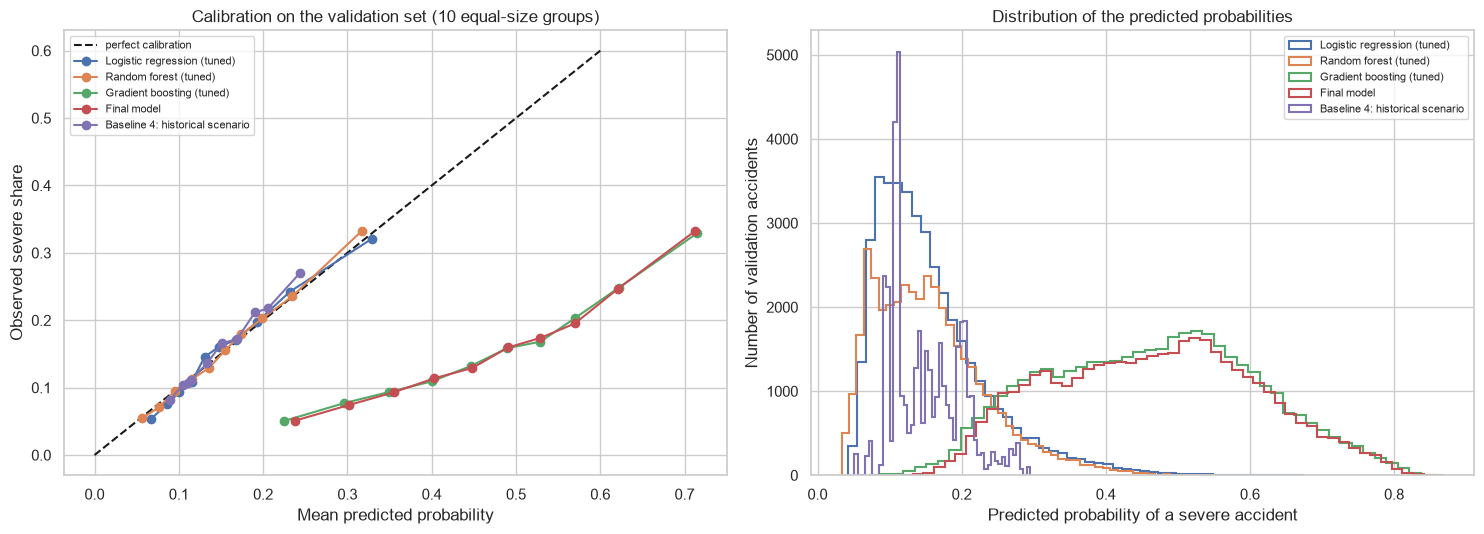

,Brier score,mean predicted (%),observed (%),largest bin gap (pp),predicted range (%)
model,,,,,
Logistic regression (tuned),0.1262,15.6894,15.6935,1.5144,4.2 to 67.5
Random forest (tuned),0.1256,15.6097,15.6935,1.5512,3.3 to 55.1
Gradient boosting (tuned),0.2246,46.4112,15.6935,38.5654,7.1 to 86.9
Final model,0.2256,46.6865,15.6935,38.0022,11.7 to 85.6
Baseline 4: historical scenario,0.1290,15.0597,15.6935,2.6484,5.1 to 29.5


In [46]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

calibration_inputs = {f"{name} (tuned)": p for name, (p, _) in tuned_probabilities.items()}
calibration_inputs["Final model"] = p_val_final
calibration_inputs["Baseline 4: historical scenario"] = p_val_b4

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].plot([0, 0.6], [0, 0.6], "k--", label="perfect calibration")
for name, probabilities in calibration_inputs.items():
    observed, predicted = calibration_curve(y_val, probabilities, n_bins=10, strategy="quantile")
    axes[0].plot(predicted, observed, marker="o", label=name)
axes[0].set_xlabel("Mean predicted probability")
axes[0].set_ylabel("Observed severe share")
axes[0].set_title("Calibration on the validation set (10 equal-size groups)")
axes[0].legend(fontsize=8)

for name, probabilities in calibration_inputs.items():
    axes[1].hist(probabilities, bins=50, histtype="step", linewidth=1.5, label=name)
axes[1].set_xlabel("Predicted probability of a severe accident")
axes[1].set_ylabel("Number of validation accidents")
axes[1].set_title("Distribution of the predicted probabilities")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

calibration_rows = []
for name, probabilities in calibration_inputs.items():
    observed, predicted = calibration_curve(y_val, probabilities, n_bins=10, strategy="quantile")
    calibration_rows.append({
        "model": name,
        "Brier score": brier_score_loss(y_val, probabilities),
        "mean predicted (%)": 100 * probabilities.mean(),
        "observed (%)": 100 * y_val.mean(),
        "largest bin gap (pp)": 100 * np.abs(predicted - observed).max(),
        "predicted range (%)": f"{100 * probabilities.min():.1f} to {100 * probabilities.max():.1f}",
    })
pd.DataFrame(calibration_rows).set_index("model").round(4)

- **Random forest and logistic regression are well calibrated:** their mean predicted risk (15.6% to 15.7%) matches the observed 15.7%, and no group is off by more than about 1.5 percentage points. Baseline 4 is also close (largest gap 2.6 points).
- **The tuned gradient boosting and the final model are not calibrated:** they predict a mean risk of about **46%** when the true rate is 15.7%, with gaps of up to **38 percentage points**. The reason is `class_weight="balanced"`, chosen by the tuning: it gives severe accidents more weight, which pushes all probabilities up.
- **This does not hurt F1 or the ranking:** the threshold (0.53 instead of about 0.17) compensates for the shift, and PR-AUC is unchanged. But these probabilities must **not** be shown to a user as a real risk ("46% chance of a severe outcome" would be wrong).

**Consequence:** if the product shows probabilities, we either use the tuned **random forest** (same F1 = 0.341, well calibrated), or we **recalibrate** the gradient boosting (for example sigmoid calibration learned on out-of-fold predictions, as Jishnu did).

## 18. Checking the Final Model: Error Analysis by Group (Idea from Jishnu)

An overall F1 can hide groups where the model works poorly. For the **final model**, we check each group on the validation set from two angles:

- **Calibration view (Jishnu):** does the **mean predicted probability** match the **observed severe share**? A positive gap means the model overestimates the risk in that group.
- **F1 view (ours):** at the cross-validated threshold, how many of the group's severe accidents does the model **find** (recall), and how many accidents does it **flag**?

Groups overlap (an accident can be at night, at the weekend and involve a motorcycle). Groups with fewer than 200 validation accidents are marked as small: their numbers are uncertain.

In [47]:
error_view =val[["state_name", "is_night", "is_weekend", "urbanisation", "population_per_km2", "vulnerable",
                  "is_severe"] + PARTICIPANTS].copy()
error_view["probability"] = p_val_final
error_view["flagged"] = flags_final
error_view["time of day"] = np.where(error_view["is_night"] == 1, "night (22-05)", "day")
error_view["day type"] = np.where(error_view["is_weekend"] == 1, "weekend", "weekday")
_, density_edges = pd.qcut(train["population_per_km2"], q=5, retbins=True)  # edges from training data only
density_edges[0], density_edges[-1] = -np.inf, np.inf
error_view["density quintile"] = pd.cut(error_view["population_per_km2"], density_edges,
                                        labels=[f"Q{i} ({'rural' if i == 1 else 'urban' if i == 5 else 'mid'})"
                                                for i in range(1, 6)])

group_rows = []
for group in ["state_name", "time of day", "day type", "urbanisation", "density quintile", "vulnerable"] + PARTICIPANTS:
    for value, part in error_view.groupby(group, observed=True):
        if group in PARTICIPANTS + ["vulnerable"] and value == 0:
            continue  # for flags we only show the accidents where the road user is involved
        severe_part = part[part["is_severe"] == 1]
        group_rows.append({
            "group": group, "value": value, "accidents": len(part),
            "observed severe (%)": 100 * part["is_severe"].mean(),
            "mean predicted (%)": 100 * part["probability"].mean(),
            "gap (pp)": 100 * (part["probability"].mean() - part["is_severe"].mean()),
            "flagged (%)": 100 * part["flagged"].mean(),
            "recall": severe_part["flagged"].mean() if len(severe_part) else np.nan,
            "small group": len(part) < 200,
        })
group_errors = pd.DataFrame(group_rows)
with pd.option_context("display.max_rows", None):
    display(group_errors.round(2))

,group,value,accidents,observed severe (%),mean predicted (%),gap (pp),flagged (%),recall,small group
0,state_name,Baden-Württemberg,4740,15.13,46.57,31.45,34.47,0.55,False
1,state_name,Bayern,7072,16.77,48.23,31.45,40.03,0.61,False
2,state_name,Berlin,1920,12.24,39.41,27.17,17.76,0.35,False
3,state_name,Brandenburg,1265,17.15,49.49,32.34,44.19,0.65,False
4,state_name,Bremen,400,8.50,32.09,23.59,6.00,0.09,False
5,state_name,Hamburg,1089,7.81,31.28,23.48,3.86,0.07,False
6,state_name,Hessen,2831,15.90,45.60,29.71,32.78,0.51,False
7,state_name,Mecklenburg-Vorpommern,727,17.74,53.54,35.80,56.95,0.75,False
8,state_name,Niedersachsen,3644,15.15,45.32,30.17,29.45,0.45,False
9,state_name,Nordrhein-Westfalen,9218,14.24,45.80,31.55,30.59,0.49,False


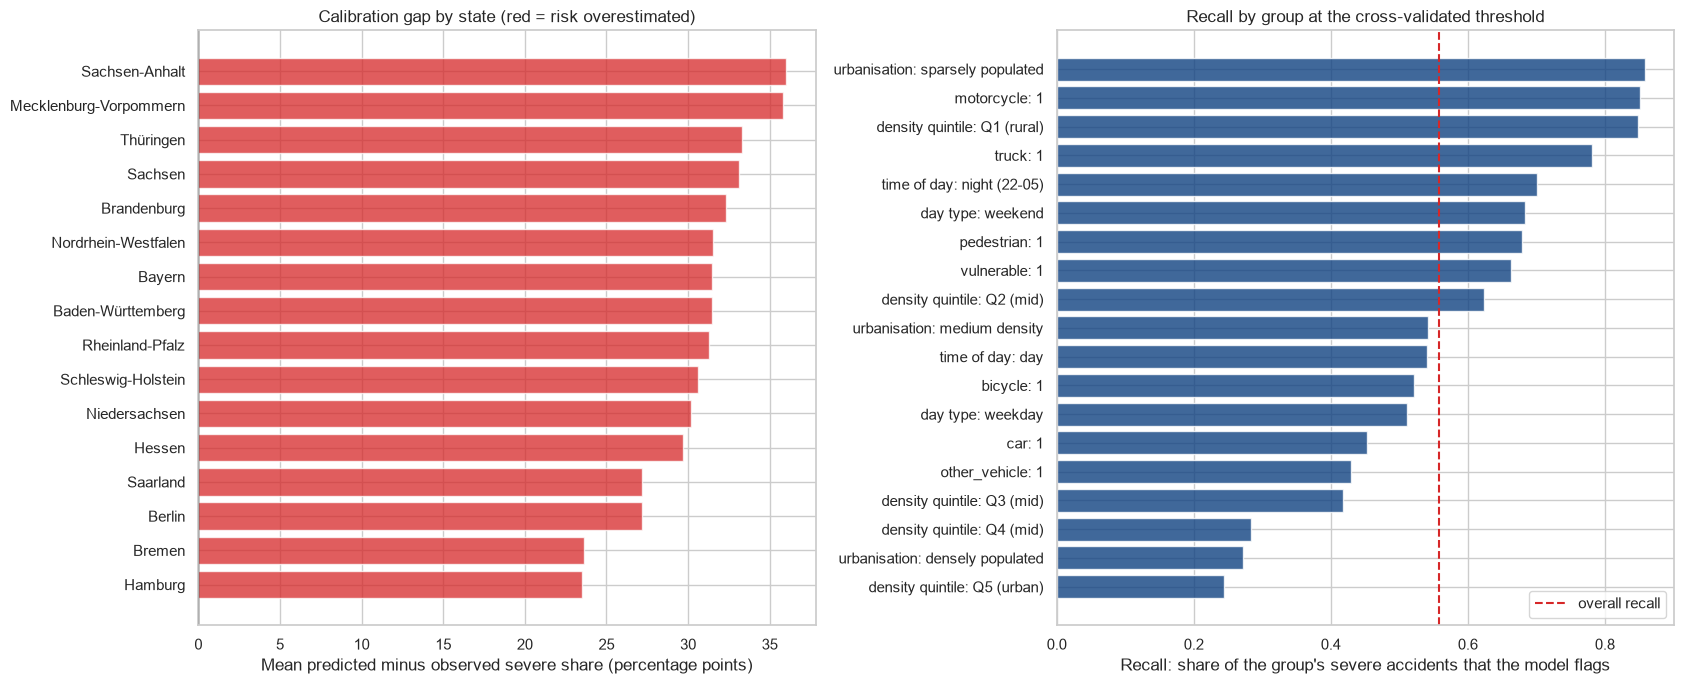

Largest calibration gaps (groups with at least 200 accidents):
               group                   value  accidents  observed severe (%)  \
32        motorcycle                       1       5454                24.40   
23  density quintile              Q1 (rural)       8298                24.26   
13        state_name          Sachsen-Anhalt       1088                18.29   
22      urbanisation      sparsely populated       7452                24.84   
7         state_name  Mecklenburg-Vorpommern        727                17.74   

    mean predicted (%)  gap (pp)  
32               61.05     36.65  
23               60.50     36.24  
13               54.30     36.01  
22               60.79     35.95  
7                53.54     35.80  


In [48]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

states = group_errors[group_errors["group"] == "state_name"].sort_values("gap (pp)")
axes[0].barh(states["value"], states["gap (pp)"],
             color=np.where(states["gap (pp)"] > 0, "tab:red", "tab:blue"), alpha=0.75)
axes[0].axvline(0, color="black", linewidth=1)
axes[0].set_xlabel("Mean predicted minus observed severe share (percentage points)")
axes[0].set_title("Calibration gap by state (red = risk overestimated)")

others = group_errors[group_errors["group"] != "state_name"].copy()
others["label"] = others["group"] + ": " + others["value"].astype(str)
others = others.sort_values("recall")
axes[1].barh(others["label"], others["recall"], color="#104281", alpha=0.8)
axes[1].axvline(recall_score(y_val, flags_final), color="tab:red", linestyle="--", label="overall recall")
axes[1].set_xlabel("Recall: share of the group's severe accidents that the model flags")
axes[1].set_title("Recall by group at the cross-validated threshold")
axes[1].legend()
plt.tight_layout()
plt.show()

print("Largest calibration gaps (groups with at least 200 accidents):")
print(group_errors[~group_errors["small group"]].reindex(
    group_errors[~group_errors["small group"]]["gap (pp)"].abs().sort_values(ascending=False).index
).head(5)[["group", "value", "accidents", "observed severe (%)", "mean predicted (%)", "gap (pp)"]].round(2))

**Calibration view:** because the final model's probabilities are shifted up by about 31 percentage points everywhere (see the calibration section), the gaps per group are all large and positive. They mainly show this overall shift, not group-specific problems, so we focus on the **recall view** for this model.

**Recall view, the main finding: the model finds severe accidents in rural areas, but misses most of them in cities.**

| Group | Observed severe | Flagged | Recall |
|---|---|---|---|
| Sparsely populated municipalities | 24.8% | 76% | **0.86** |
| Densely populated municipalities | 10.8% | 14% | **0.27** |
| Least dense fifth of accidents (rural) | 24.3% | 76% | **0.85** |
| Densest fifth (urban) | 10.0% | 12% | **0.24** |
| Hamburg | 7.8% | 4% | **0.07** |
| Bremen | 8.5% | 6% | **0.09** |
| Berlin | 12.2% | 18% | **0.35** |
| Thuringia | 24.8% | 71% | **0.80** |
| Motorcycle involved | 24.4% | 74% | **0.85** |
| Night (22:00 to 05:59) | 20.8% | 60% | **0.70** |

- The model has learned the strongest pattern in the data (rural = more severe) and **leans on it heavily**: it flags three quarters of rural accidents and very few urban ones.
- As a result, **severe accidents in cities are mostly missed**: only 7% in Hamburg, 9% in Bremen and 24% in the densest areas are found. In absolute numbers this matters, because cities have many accidents.
- High-risk groups such as motorcycles (0.85), rural roads and nights are found well.

**Implication for the stakeholders:** the model is useful for prioritising **rural** prevention, but it should not be used to judge urban safety. A separate threshold per area type, or a model focused on urban accidents, would be a possible next step.

## 19. Reference Model with Post-Accident Information (Not a Baseline)

> ⚠️ **This is a reference model, not a baseline, and not a model we can use.**
> It uses `accident_kind` and `accident_type`, which describe **how the accident happened** and are only known **after** it. In Scenario C we predict **before** an accident, so this information is never available. A model that uses it would be **data leakage** in our scenario.
>
> **Our models do not have to beat it.** If they score lower, that is expected and not a failure: they work with less information.

### Why Do We Build It Anyway?

Tiziano's baselines and Zina's notebook compare with a model that uses the accident kind and type. Zina's summary says that her Scenario C model reaches about the same F1 on the test set (0.338) as Tiziano's logistic regression **with** kind and type (0.338). That comparison is not fully fair: Tiziano's model is a **logistic regression**, while Zina's is a **tuned gradient boosting**, so part of the tie comes from the stronger model type.

Here we answer the question in a fair way: **how much do we lose by predicting before the accident?** We train the **same model** (gradient boosting with the same settings), on the **same feature set B**, with the **same threshold method** (5-fold cross validation), and only add `accident_kind` and `accident_type`. The difference between the two models is the **price of Scenario C**.

In [49]:
REFERENCE_SET = dict(FEATURE_SETS["B: + density (Zina)"],
                     nominal=["state", "accident_kind", "accident_type"])  # + post-accident columns
reference_columns = set_columns(REFERENCE_SET)

# X_train / X_val contain only Scenario C features, so we take the columns from the full split tables
X_train_reference, X_val_reference = train[reference_columns], val[reference_columns]

reference_model = make_pipeline(make_set_preprocessor(REFERENCE_SET), clone(MODELS["Gradient boosting"]))
oof_reference = cross_val_predict(reference_model, X_train_reference, y_train, cv=CV,
                                  method="predict_proba")[:, 1]
reference_threshold, reference_cv_f1 = best_f1_threshold(y_train, oof_reference)

reference_model.fit(X_train_reference, y_train)
p_val_reference = reference_model.predict_proba(X_val_reference)[:, 1]
reference_flags = (p_val_reference >= reference_threshold).astype(int)
print("Reference model: CV F1 %.3f, threshold %.3f" % (reference_cv_f1, reference_threshold))

Reference model: CV F1 0.367, threshold 0.184


### Comparison: Baselines, Our Model, and the Reference

The table keeps the three roles apart:

- **Baselines** are simple rules we must beat.
- **Our Scenario C model** is the gradient boosting on set B from above (same model and settings as the reference).
- **The reference** shows what would be possible **after** the accident. It is not a target.

In [50]:
def summary_row(role, name, usable, y_true, p=None, flags=None):
    """One row of the comparison table (probabilities are optional for rules)."""
    return {
        "role": role, "model": name, "usable in Scenario C": usable,
        "val PR-AUC": average_precision_score(y_true, p) if p is not None else np.nan,
        "val precision": precision_score(y_true, flags, zero_division=0),
        "val recall": recall_score(y_true, flags),
        "val F1": f1_score(y_true, flags),
    }


scenario_c_key = ("B: + density (Zina)", "Gradient boosting")
scenario_c_flags = (val_probabilities[scenario_c_key] >= model_results.loc[scenario_c_key, "threshold"]).astype(int)

comparison = pd.DataFrame([
    summary_row("Baseline", "Baseline 1: majority class", "yes", y_val, flags=majority.predict(X_val)),
    summary_row("Baseline", "Baseline 3: rule without leakage", "yes", y_val, flags=baseline_3_rule(X_val)),
    summary_row("Our model", "Gradient boosting, set B (Scenario C)", "yes", y_val,
                p=val_probabilities[scenario_c_key], flags=scenario_c_flags),
    summary_row("Reference only", "Gradient boosting, set B + accident kind/type", "NO (post-accident)",
                y_val, p=p_val_reference, flags=reference_flags),
]).set_index(["role", "model"])
comparison.round(3)

usable in Scenario C  \
role           model                                                                
Baseline       Baseline 1: majority class                                     yes   
               Baseline 3: rule without leakage                               yes   
Our model      Gradient boosting, set B (Scenario C)                          yes   
Reference only Gradient boosting, set B + accident kind/type   NO (post-accident)   

                                                              val PR-AUC  \
role           model                                                       
Baseline       Baseline 1: majority class                            NaN   
               Baseline 3: rule without leakage                      NaN   
Our model      Gradient boosting, set B (Scenario C)               0.272   
Reference only Gradient boosting, set B + accident kind/type       0.302   

                                                              val precision  \
role           model                                                          
Baseline       Baseline 1: majority class                             0.000   
               Baseline 3: rule without leakage                       0.210   
Our model      Gradient boosting, set B (Scenario C)                  0.239   
Reference only Gradient boosting, set B + accident kind/type          0.275   

                                                              val recall  \
role           model                                                       
Baseline       Baseline 1: majority class                          0.000   
               Baseline 3: rule without leakage                    0.541   
Our model      Gradient boosting, set B (Scenario C)               0.599   
Reference only Gradient boosting, set B + accident kind/type       0.569   

                                                              val F1  
role           model                                                  
Baseline       Baseline 1: majority class                      0.000  
               Baseline 3: rule without leakage                0.303  
Our model      Gradient boosting, set B (Scenario C)           0.341  
Reference only Gradient boosting, set B + accident kind/type   0.371

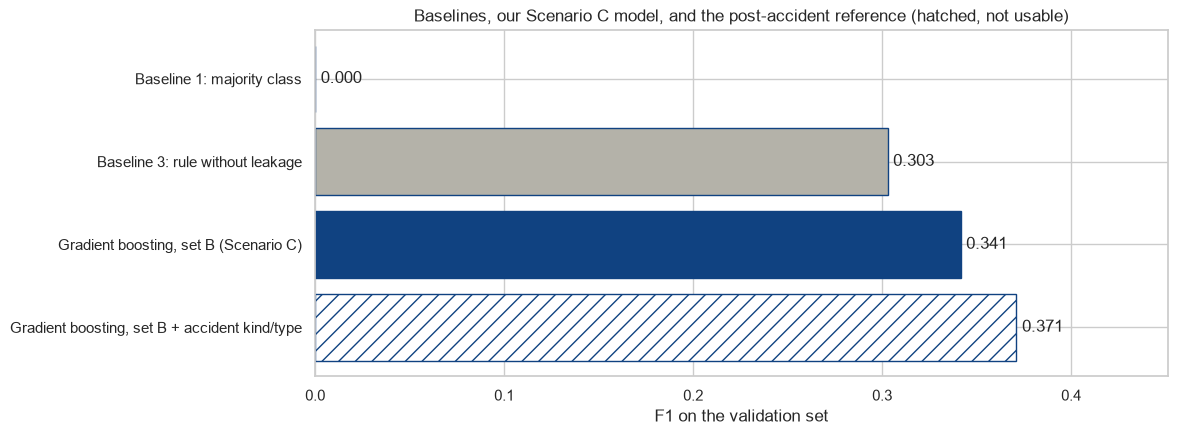

Price of Scenario C (reference F1 minus our F1): 0.030
Our gain over Baseline 3: 0.039


In [51]:
colors = {"Baseline": "#b4b2a9", "Our model": "#104281", "Reference only": "white"}
labels = [m for _, m in comparison.index]
values = comparison["val F1"].to_numpy()

fig, ax = plt.subplots(figsize=(11, 4.5))
bars = ax.barh(labels, values, color=[colors[r] for r, _ in comparison.index], edgecolor="#104281")
bars[-1].set_hatch("//")
ax.bar_label(bars, fmt="%.3f", padding=4)
ax.invert_yaxis()
ax.set_xlim(0, max(values) + 0.08)
ax.set_xlabel("F1 on the validation set")
ax.set_title("Baselines, our Scenario C model, and the post-accident reference (hatched, not usable)")
plt.show()

price = comparison["val F1"].iloc[3] - comparison["val F1"].iloc[2]
print("Price of Scenario C (reference F1 minus our F1): %.3f" % price)
print("Our gain over Baseline 3: %.3f" % (comparison["val F1"].iloc[2] - comparison["val F1"].iloc[1]))

| | Validation F1 | PR-AUC | Meaning |
|---|---|---|---|
| Baseline 3 (rule) | 0.303 | n/a | The simple rule our model must beat |
| **Our model** (gradient boosting, set B) | **0.341** | 0.272 | Scenario C, usable before an accident |
| Reference (same model + accident kind/type) | 0.371 | 0.302 | **Not usable** in Scenario C |

- **Our model beats Baseline 3 by 0.039 F1.** This is the comparison that counts.
- **The price of Scenario C is 0.030 F1** (and 0.030 PR-AUC): that is how much better the **same** model gets when it may also know how the accident happened. The reference is mainly **more precise** (0.275 versus 0.239): knowing that a car left the road or hit an oncoming car makes the severe accidents easier to separate.
- So our model closes more than half of the gap between the simple rule (0.303) and the post-accident reference (0.371), **without** any post-accident information.

**Why this differs from Zina's summary:** with the **same model type** on both sides, post-accident information does help (0.341 → 0.371). The tie in Zina's notebook (0.338 versus 0.338 on test) came from comparing a tuned gradient boosting with a plain logistic regression.

### How to Talk About the Reference (for the Presentation)

✅ **Correct:**
- "Our model predicts severity **before** an accident and beats the simple rule (Baseline 3) by 0.04 F1."
- "A model that is allowed to know **how** the accident happened reaches F1 = 0.37. Predicting before the accident costs us about 0.03 F1."

❌ **Not correct:**
- "Our model is worse than the baseline with accident kind and type." (It is not a baseline; it uses information we cannot have.)
- "Our model is as good as a model with post-accident information." (Only true when you compare a stronger model type with a weaker one, as in the logistic regression comparison.)

> *The reference model uses information that is only known after the accident. It is not a baseline we can deploy, but it shows how much performance we give up by predicting before the accident.*

## 20. Next Steps

1. **Agree on one split for the whole team** before the final test: Jishnu's notebooks use their own split (stratified by `severe`), so his validation and test accidents differ from Tiziano's split used here.
2. **Probabilities:** if the product shows a risk in percent, use the tuned random forest (well calibrated, same F1) or recalibrate the gradient boosting with sigmoid calibration learned on out-of-fold predictions.
3. **Urban accidents:** the model misses most severe accidents in cities (recall 0.07 to 0.35 in the city states). Test a separate threshold per urbanisation level, chosen with cross validation.
4. **Simplify:** drop the feature groups that add nothing in the ablation (state age shares, `single_type`, interactions, region keys) and confirm with cross validation that the score stays the same.
5. **Only at the very end, once:** evaluate the final model on the test set with its cross-validated threshold, and compare it with Baselines 1, 3 and 4 on the test set.